# Alliston steady-state groundwater flow model

This is a conversion of the ALLISTON groundwater flow model developed for the [South Simcoe Municipal Groundwater study (2004)](https://www.dropbox.com/scl/fi/r4nc1p6pckj7pv2x1smfz/Golder_2004_South-Simcoe-Municipal-Groundwater-Study.-August_2613.pdf?rlkey=sul4lx05f42nmlkwm0m9zvy5v&st=lbl2jtq5&dl=1). 

Notes:

- The model was originally built in 2003 using visualMODFLOW (2001 Waterloo Hydrogeologic Software). 
- The [original 2003 MODFLOW files](https://www.dropbox.com/scl/fi/zyo1ndf8v5d1914mh5u7n/2003-MODFLOW-files.7z?rlkey=qbnnpltfqtvmp7isyqq578ggq&st=11qxldfa&dl=1) obtained by the [ORMGP](oakridgeswater.ca) was converted into a raw binary format compatible as input to [FloPy](https://flopy.readthedocs.io/en/stable/).
- The following jupyter notebook re-builds the model in MODFLOW6 to generate a steady-state solution using the Newton-Raphson formulation.
- The model coordinates were estimated by georeferencing Figure 2.3.1 (below). Using this transformation, the model domain has been used to generate [boundary shapefiles](https://www.dropbox.com/scl/fi/0h9mkni0749e5v3p42qga/ALLISTON-shapefiles.7z?rlkey=0t1x9x1e09xo3mkocgtfen8sy&st=llxo12ss&dl=1):
    - `ALLISTONactive_actives.shp`: the active model cells, attributed with model row and column indices
    - `ALLISTONactive_bound.shp`: the outer model boundary
    - both files are projected to UTM zone 17N, [EPSG:26917](https://epsg.io/26917).
- Much of this code was adapted from: https://flopy.readthedocs.io/en/latest/examples.html -- a great resources for working with FloPy.
- Particle tracking is included below and uses [MODPATH7](https://www.usgs.gov/software/modpath-a-particle-tracking-model-modflow).

![](doc/Newt_Figure_231.png)

> Be aware that MODFLOW uses a 1-base array system, so take care when referring the MODFLOW row/column/layer indices to (zero-based) python indices. (e.g., MODFLOW's (row,column,layer) (1,1,1) is python's (0,0,0).)

Created by M. Marchildon, 2026

### Load packages

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import flopy
from flopy.modpath import ParticleGroup, ParticleData, Modpath7Sim
print(np.__version__)
print(flopy.__version__)

2.3.3
3.9.5


### Model location and name
> Hint: keep this jupyter notebook in the same directory as the `input_MODFLOW/` directory to keep `root = './'`.

Change the `nam` variable to reflect a simulation scenario, the script below will create a new model directory with the model name given. (Must keep the name 16-characters long, max.)

In [2]:
root = './' # root location where the input_MODFLOW directory sits and where model simulations are placed.
nam = "Alliston-SS"  # model name must be less than 16 characters long
if not os.path.exists(root+nam): os.mkdir(root+nam) # create model directory

#### Model spatial structure
- grid definition and layer thicknesses
- layers are ordered form top down in MODFLOW
- do not modify

In [ ]:
# from ALLISTON.DIS
nrow = 166
ncol = 197
nlay = 7
delr = [200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 100., 50., 50., 25., 25., 25., 25., 25., 25., 50., 50., 50., 100., 100., 50., 50., 50., 25., 25., 25., 25., 25., 25., 50., 50., 50., 50., 25., 25., 25., 25., 25., 25., 50., 50., 50., 100., 100., 100., 100., 100., 100., 100., 100., 50., 50., 25., 25., 25., 25., 25., 25., 50., 50., 50., 100., 50., 50., 50., 25., 25., 25., 25., 25., 25., 25., 25., 25., 25., 50., 50., 100., 100., 50., 50., 50., 25., 25., 25., 25., 25., 25., 50., 50., 100., 200., 200., 200., 200., 200., 200., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 200., 200., 200., 200., 200.]
delc = [200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 100., 100., 50., 50., 25., 25., 50., 50., 50., 100., 100., 100., 50., 50., 25., 25., 50., 50., 50., 50., 50., 25., 25., 25., 25., 25., 25., 50., 50., 50., 100., 200., 200., 200., 200., 200., 100., 50., 50., 25., 25., 25., 25., 25., 25., 50., 50., 50., 100., 200., 200., 200., 100., 50., 50., 25., 25., 25., 25., 25., 25., 50., 50., 50., 100., 100., 50., 50., 50., 25., 25., 25., 25., 25., 25., 25., 25., 50., 50., 50., 100., 100., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200., 200.]

# geo-referencing
xll = 580775  # lower-left x grid coordinate (UTM zone 17; EPSG:26917)
yll = 4873540 # lower-left y grid coordinate (UTM zone 17; EPSG:26917)
rot = 0.3159  # counter-clockwise rotation in radians

top = np.fromfile(root+"input_MODFLOW/ALLISTON_TOP.bin",dtype=np.float32).reshape((ncol,nrow)).T # top of model
botm = np.ones((nlay, nrow, ncol), dtype=np.float32) # bottom of all 7 layers
for k in range(nlay): botm[k,:,:] = np.fromfile(root+"input_MODFLOW/ALLISTON_BOTM_{}.bin".format(k+1),dtype=np.float32).reshape((ncol,nrow)).T

#### Model domain and initial conditions
The `ibound` is used to deactivate grid cells that are not part of the model domain 

In [4]:
# from ALLISTON.BAS
ibound = np.zeros((nlay, nrow, ncol), dtype=np.int16)
for k in range(nlay):
    ibound[k,:,:] = np.fromfile(root+"input_MODFLOW/ALLISTON_IBOUND_{}.bin".format(k+1),dtype=np.int16).reshape((ncol,nrow)).T

strt = np.zeros((nlay, nrow, ncol), dtype=np.float32) # initial (head) conditions
for k in range(nlay):
    if k+1 in [1,2,4,6]:
        strt[k,:,:] = np.ones((nrow,ncol), dtype=np.float32)*4.1667e2 # specified as a constant in ALLISTON.BAS
    else:
        strt[k,:,:] = np.fromfile(root+"input_MODFLOW/ALLISTON_STRT_{}.bin".format(k+1),dtype=np.float32).reshape((ncol,nrow)).T

#### Material properties (hydraulic conductivity) and layer types 

In [5]:
# from ALLISTON.BCF
laytyp = [3, 3, 3, 3, 3, 3, 3] # 3: confined/unconfined—Transmissivity of the layer varies. It is calculated from the saturated thickness and hydraulic conductivity. The storage coefficient may alternate between confined and unconfined values. Vertical flow from above is limited if the aquifer desaturates.

k11 = np.zeros((nlay,nrow,ncol), dtype=np.float32) # hydraulic conductivity in the horizontal
for k in range(nlay):
    k11[k] = np.fromfile(root+"input_MODFLOW/ALLISTON_HK_{}.bin".format(k+1),dtype=np.float32).reshape((ncol,nrow)).T

vcont = np.zeros((nlay-1,nrow,ncol), dtype=np.float32) # VCONT: the vertical hydraulic conductivity divided by the thickness from a layer to the layer below. 
for k in range(nlay-1):
    vcont[k] = np.fromfile(root+"input_MODFLOW/ALLISTON_VCONT_{}.bin".format(k+1),dtype=np.float32).reshape((ncol,nrow)).T



#### Extracting vertical conductivity $(K_\text{33})$ from $VCONT$
In the version of MODFLOW originally used, $VCONT$ "the vertical hydraulic conductivity divided by the thickness from a layer to the layer below."

In MODFLOW6 using the Newton-Raphson solver requires that a vertical hydraulic conductivity $(K_\text{33})$ be be assigned to each layer. Conversion from $VCONT$ is determined assuming a harmonic mean. Vertical conductivity of layer $k$ is determined using:

$$
    K_\text{33} = VCONT_{k,k+1}\cdot \tfrac{1}{2}\left(\Delta z_k + \Delta z_{k+1}\right)
$$

In [6]:
def vcont_to_k33(top, botm, vcont, eps=1e-30):
    # thickness
    thk = np.empty_like(botm, dtype=np.float32)
    thk[0] = top - botm[0]
    thk[1:] = botm[:-1] - botm[1:]
    thk = np.clip(thk, 0.0, np.inf)

    # implied k33 from each adjacent interface (VCONT) then harmonic-combine per cell
    k_above = np.full_like(thk, np.nan)
    k_below = np.full_like(thk, np.nan)

    # interface below layer k is vcont[k]  (k = 0..nlay-2)
    k_below[:-1] = 2.0 * vcont * thk[:-1]
    # interface above layer k is vcont[k-1] (k = 1..nlay-1)
    k_above[1:]  = 2.0 * vcont * thk[1:]

    # harmonic combine; if only one side exists, use it
    a = np.where(k_above > 0, k_above, np.nan)
    b = np.where(k_below > 0, k_below, np.nan)

    k33 = 2.0 / (1.0 / np.maximum(a, eps) + 1.0 / np.maximum(b, eps))
    k33 = np.where(np.isnan(a) & ~np.isnan(b), b, k33)
    k33 = np.where(~np.isnan(a) & np.isnan(b), a, k33)

    return k33

k33 = vcont_to_k33(top,botm,vcont)

## Boundary Conditions

### Groundwater Recharge
Hint: if you're ever looking to test, say, a drought scenario, simply reduce this field by some factor, say 10%.

In [7]:
recharge = np.fromfile(root+"input_MODFLOW/ALLISTON_RCH.bin",dtype=np.float32)

### Wells
Compare the following lines with the file these data output: `Alliston-SS.wel`. Here we see the zero/one-base arrays.

The pumping rates are assigned a negative values when water is *taken* from the groundwater system.

In [8]:
# from ALLISTON.WEL -- lay,row,col reverted to a zero-based indexing
wel_spd = {
    0: [ # 0 refers to timestep 0 -- this means the pumping is always on at a steady rate
        #[layer row column <pumping rate m3/day>]
        [4, 58, 101, -784],
        [3, 58, 101, -0.001252],
        [3, 101, 76, -0.0008458],
        [2, 101, 76, -1195.9],
        [1, 101, 76, -0.1107],
        [4, 66, 150, -216],
        [5, 113, 131, -0.06174],
        [4, 113, 131, -1537.9],
        [4, 118, 137, -1629],
        [4, 85, 120, -1226],
        [6, 48, 90, -404.62],
        [5, 48, 90, -5.3834],
        [4, 15, 58, -248.6],
        [4, 18, 50, -186.5],
        [2, 78, 172, -262.1],
    ]
}

### Constant head cells
In previous versions of MODFLOW, setting your ibound <0 meant holding these cells to a constant head boundary given by the initial head. MODFLOW6 requires that these boundaries be specified explicitly. The following function makes the conversion.

In [9]:
layrowcols = np.where(ibound < 0)
lays, rows, cols = layrowcols
chd_spd = []
for d in range(len(lays)):
    k,i,j = lays[d], rows[d], cols[d]
    chd_spd += [[k, i, j, strt[k,i,j]]]
chd_spd = {0: chd_spd} # set to first (and only) stress period
idomain = ibound.copy()
idomain[layrowcols]=1 # activate domain where CHD boundary exists.

### Rivers
Type-3 boundary conditions representing leakage/recharge to/from stream channels

The following code block is long, collapse these lines to make the notebook more legible.

In [10]:
# from ALLISTON.RIV -- lay,row,col reverted to a zero-based indexing
riv_spd = {
    0: [
        #[layer row column Stage Condfact Rbot]
        [0, 23, 8, 314.83, 20, 314.73],
        [0, 22, 8, 314.53, 20, 314.43],
        [0, 21, 8, 314.99, 20, 314.89],
        [0, 20, 8, 312.86, 20, 312.76],
        [0, 19, 9, 310.98, 20, 310.88],
        [0, 155, 10, 299.57, 100, 299.47],
        [0, 18, 10, 309.77, 20, 309.67],
        [0, 154, 11, 296.46, 100, 296.36],
        [0, 140, 11, 287.59, 100, 287.49],
        [0, 28, 11, 274.5, 20, 274.4],
        [0, 17, 11, 308.6, 20, 308.5],
        [0, 154, 12, 295, 100, 294.9],
        [0, 141, 12, 281.93, 100, 281.83],
        [0, 27, 12, 270.89, 20, 270.79],
        [0, 17, 12, 302.25, 20, 302.15],
        [0, 158, 13, 259, 100, 258.9],
        [0, 153, 13, 295.17, 100, 295.07],
        [0, 141, 13, 278.18, 100, 278.08],
        [0, 26, 13, 270.1, 20, 270],
        [0, 18, 13, 298.42, 20, 298.32],
        [0, 158, 14, 255.94, 100, 255.84],
        [0, 153, 14, 293.96, 100, 293.86],
        [0, 140, 14, 275.37, 100, 275.27],
        [0, 26, 14, 267.84, 20, 267.74],
        [0, 18, 14, 300.41, 20, 300.31],
        [0, 158, 15, 255.6, 100, 255.5],
        [0, 152, 15, 294.01, 100, 293.91],
        [0, 140, 15, 269.82, 100, 269.72],
        [0, 38, 15, 276.13, 20, 276.03],
        [0, 26, 15, 265.87, 20, 265.77],
        [0, 18, 15, 294.04, 20, 293.94],
        [0, 158, 16, 256.09, 100, 255.99],
        [0, 152, 16, 289.45, 100, 289.35],
        [0, 140, 16, 266.17, 100, 266.07],
        [0, 131, 16, 265, 100, 264.9],
        [0, 37, 16, 274.94, 20, 274.84],
        [0, 26, 16, 264.94, 20, 264.84],
        [0, 18, 16, 288.52, 20, 288.42],
        [0, 157, 17, 255, 100, 254.9],
        [0, 152, 17, 284.21, 100, 284.11],
        [0, 140, 17, 263.99, 100, 263.89],
        [0, 134, 17, 299.15, 100, 299.05],
        [0, 131, 17, 263.39, 100, 263.29],
        [0, 37, 17, 270.01, 20, 269.91],
        [0, 27, 17, 263.4, 20, 263.3],
        [0, 18, 17, 284.02, 20, 283.92],
        [0, 157, 18, 254, 100, 253.9],
        [0, 152, 18, 287.62, 100, 287.52],
        [0, 140, 18, 263.07, 100, 262.97],
        [0, 135, 18, 290.62, 100, 290.52],
        [0, 130, 18, 259.97, 100, 259.87],
        [0, 37, 18, 268, 20, 267.9],
        [0, 27, 18, 260.19, 20, 260.09],
        [0, 18, 18, 280.61, 20, 280.51],
        [0, 157, 19, 253.98, 100, 253.88],
        [0, 152, 19, 287.91, 100, 287.81],
        [0, 140, 19, 261.64, 100, 261.54],
        [0, 137, 19, 273.94, 100, 273.84],
        [0, 136, 19, 283.02, 100, 282.92],
        [0, 130, 19, 257, 100, 256.9],
        [0, 37, 19, 265.76, 20, 265.66],
        [0, 27, 19, 259.05, 20, 258.95],
        [0, 21, 19, 293.11, 20, 293.01],
        [0, 20, 19, 282.45, 20, 282.35],
        [0, 19, 19, 279.1, 20, 279],
        [0, 18, 19, 273.1, 20, 273],
        [0, 156, 20, 251.01, 100, 250.91],
        [0, 151, 20, 277.34, 100, 277.24],
        [0, 140, 20, 259.43, 100, 259.33],
        [0, 138, 20, 260.97, 100, 260.87],
        [0, 130, 20, 254.92, 100, 254.82],
        [0, 37, 20, 264, 20, 263.9],
        [0, 27, 20, 257.06, 20, 256.96],
        [0, 18, 20, 274.94, 20, 274.84],
        [0, 156, 21, 250, 100, 249.9],
        [0, 150, 21, 287.15, 100, 287.05],
        [0, 139, 21, 254.69, 100, 254.59],
        [0, 130, 21, 254, 100, 253.9],
        [0, 37, 21, 262.33, 20, 262.23],
        [0, 27, 21, 256, 20, 255.9],
        [0, 17, 21, 266.23, 20, 266.13],
        [0, 156, 22, 250.07, 100, 249.97],
        [0, 149, 22, 268.07, 100, 267.97],
        [0, 139, 22, 255.54, 100, 255.44],
        [0, 130, 22, 252, 100, 251.9],
        [0, 37, 22, 260.27, 20, 260.17],
        [0, 28, 22, 255, 20, 254.9],
        [0, 16, 22, 268.11, 20, 268.01],
        [0, 156, 23, 253.35, 100, 253.25],
        [0, 149, 23, 262.52, 100, 262.42],
        [0, 139, 23, 255, 100, 254.9],
        [0, 130, 23, 251, 100, 250.9],
        [0, 67, 23, 291.53, 5.0000025, 291.43],
        [0, 66, 23, 291.53, 5.0000025, 291.43],
        [0, 65, 23, 291.53, 5.0000025, 291.43],
        [0, 64, 23, 291.53, 5.0000025, 291.43],
        [0, 37, 23, 259.61, 20, 259.51],
        [0, 29, 23, 253.06, 20, 252.96],
        [0, 19, 23, 293.16, 100, 293.06],
        [0, 15, 23, 266.91, 20, 266.81],
        [0, 14, 23, 262.26, 20, 262.16],
        [0, 155, 24, 250, 100, 249.9],
        [0, 149, 24, 272.87, 100, 272.77],
        [0, 139, 24, 251.27, 100, 251.17],
        [0, 129, 24, 249.75, 100, 249.65],
        [0, 63, 24, 279.27, 10, 279.17],
        [0, 62, 24, 279.27, 10, 279.17],
        [0, 36, 24, 260.27, 20, 260.17],
        [0, 29, 24, 251.02, 20, 250.92],
        [0, 20, 24, 276.7, 100, 276.6],
        [0, 13, 24, 255.74, 20, 255.64],
        [0, 155, 25, 251.44, 100, 251.34],
        [0, 148, 25, 260.48, 100, 260.38],
        [0, 139, 25, 244.05, 100, 243.95],
        [0, 129, 25, 248, 100, 247.9],
        [0, 90, 25, 280.97, 50, 280.87],
        [0, 89, 25, 280.97, 50, 280.87],
        [0, 61, 25, 271.01, 10, 270.91],
        [0, 60, 25, 271.01, 10, 270.91],
        [0, 36, 25, 264.99, 20, 264.89],
        [0, 30, 25, 250, 20, 249.9],
        [0, 21, 25, 268.84, 100, 268.74],
        [0, 12, 25, 254, 20, 253.9],
        [0, 154, 26, 249, 100, 248.9],
        [0, 148, 26, 245.29, 100, 245.19],
        [0, 139, 26, 243.9, 100, 243.8],
        [0, 129, 26, 245.55, 100, 245.45],
        [0, 91, 26, 277.15, 100, 277.05],
        [0, 61, 26, 264.8, 10, 264.7],
        [0, 60, 26, 264.8, 10, 264.7],
        [0, 36, 26, 260.56, 20, 260.46],
        [0, 33, 26, 250, 20, 249.9],
        [0, 32, 26, 250, 20, 249.9],
        [0, 31, 26, 250, 20, 249.9],
        [0, 21, 26, 263.9, 100, 263.8],
        [0, 11, 26, 253.11, 20, 253.01],
        [0, 153, 27, 248.95, 100, 248.85],
        [0, 152, 27, 248.14, 100, 248.04],
        [0, 151, 27, 247, 100, 246.9],
        [0, 150, 27, 246, 100, 245.9],
        [0, 149, 27, 245.89, 100, 245.79],
        [0, 148, 27, 245, 100, 244.9],
        [0, 147, 27, 244, 100, 243.9],
        [0, 139, 27, 239.11, 100, 239.01],
        [0, 129, 27, 244.06, 100, 243.96],
        [0, 91, 27, 272.33, 100, 272.23],
        [0, 61, 27, 261.44, 10, 261.34],
        [0, 60, 27, 261.44, 10, 261.34],
        [0, 36, 27, 256.01, 20, 255.91],
        [0, 31, 27, 250, 20, 249.9],
        [0, 22, 27, 261.35, 100, 261.25],
        [0, 11, 27, 250.06, 20, 249.96],
        [0, 146, 28, 244, 100, 243.9],
        [0, 145, 28, 243.95, 100, 243.85],
        [0, 144, 28, 243, 100, 242.9],
        [0, 139, 28, 238.48, 100, 238.38],
        [0, 128, 28, 243, 100, 242.9],
        [0, 90, 28, 269.42, 50, 269.32],
        [0, 89, 28, 269.42, 50, 269.32],
        [0, 63, 28, 260.97, 10, 260.87],
        [0, 62, 28, 260.97, 10, 260.87],
        [0, 35, 28, 251.16, 20, 251.06],
        [0, 31, 28, 249, 20, 248.9],
        [0, 22, 28, 259.98, 100, 259.88],
        [0, 11, 28, 250, 20, 249.9],
        [0, 143, 29, 240.13, 100, 240.03],
        [0, 142, 29, 240, 100, 239.9],
        [0, 141, 29, 240, 100, 239.9],
        [0, 140, 29, 239, 100, 238.9],
        [0, 139, 29, 238, 100, 237.9],
        [0, 127, 29, 241.81, 100, 241.71],
        [0, 90, 29, 265.06, 50, 264.96],
        [0, 89, 29, 265.06, 50, 264.96],
        [0, 63, 29, 256.04, 10, 255.94],
        [0, 62, 29, 256.04, 10, 255.94],
        [0, 36, 29, 252.97, 20, 252.87],
        [0, 31, 29, 247.99, 20, 247.89],
        [0, 22, 29, 256.65, 100, 256.55],
        [0, 11, 29, 249.3, 20, 249.2],
        [0, 138, 30, 237.73, 100, 237.63],
        [0, 127, 30, 239.6, 100, 239.5],
        [0, 123, 30, 242.07, 100, 241.97],
        [0, 122, 30, 242.24, 50, 242.14],
        [0, 121, 30, 242.24, 50, 242.14],
        [0, 91, 30, 263.87, 100, 263.77],
        [0, 63, 30, 252.83, 10, 252.73],
        [0, 62, 30, 252.83, 10, 252.73],
        [0, 36, 30, 253.83, 20, 253.73],
        [0, 31, 30, 245.83, 20, 245.73],
        [0, 23, 30, 254.51, 100, 254.41],
        [0, 11, 30, 247.21, 20, 247.11],
        [0, 137, 31, 236.93, 100, 236.83],
        [0, 126, 31, 239, 100, 238.9],
        [0, 124, 31, 239, 100, 238.9],
        [0, 120, 31, 243.99, 50, 243.89],
        [0, 119, 31, 243.99, 25, 243.89],
        [0, 118, 31, 243.99, 25, 243.89],
        [0, 117, 31, 245, 25, 244.9],
        [0, 116, 31, 245, 25, 244.9],
        [0, 115, 31, 245, 25, 244.9],
        [0, 114, 31, 245, 25, 244.9],
        [0, 113, 31, 246.07, 25, 245.97],
        [0, 112, 31, 246.07, 25, 245.97],
        [0, 111, 31, 246.07, 50, 245.97],
        [0, 104, 31, 249.89, 50, 249.79],
        [0, 103, 31, 249.89, 25, 249.79],
        [0, 102, 31, 249.89, 25, 249.79],
        [0, 101, 31, 249.94, 25, 249.84],
        [0, 100, 31, 249.94, 25, 249.84],
        [0, 99, 31, 249.94, 25, 249.84],
        [0, 98, 31, 249.94, 25, 249.84],
        [0, 97, 31, 250.25, 50, 250.15],
        [0, 96, 31, 250.25, 50, 250.15],
        [0, 95, 31, 250.29, 100, 250.19],
        [0, 94, 31, 254, 100, 253.9],
        [0, 93, 31, 258.85, 100, 258.75],
        [0, 92, 31, 259.19, 100, 259.09],
        [0, 63, 31, 246, 10, 245.9],
        [0, 62, 31, 246, 10, 245.9],
        [0, 35, 31, 246.29, 20, 246.19],
        [0, 32, 31, 244.59, 20, 244.49],
        [0, 23, 31, 252, 100, 251.9],
        [0, 11, 31, 246.93, 20, 246.83],
        [0, 136, 32, 238.08, 100, 237.98],
        [0, 126, 32, 238.8, 100, 238.7],
        [0, 125, 32, 239, 100, 238.9],
        [0, 110, 32, 246, 50, 245.9],
        [0, 109, 32, 246, 50, 245.9],
        [0, 108, 32, 247.17, 100, 247.07],
        [0, 107, 32, 249, 100, 248.9],
        [0, 106, 32, 249.66, 50, 249.56],
        [0, 105, 32, 249.66, 50, 249.56],
        [0, 61, 32, 244.24, 10, 244.14],
        [0, 60, 32, 244.24, 10, 244.14],
        [0, 59, 32, 247.97, 10, 247.87],
        [0, 58, 32, 247.97, 5.0000025, 247.87],
        [0, 57, 32, 247.97, 5.0000025, 247.87],
        [0, 56, 32, 247.05, 10, 246.95],
        [0, 55, 32, 247.05, 10, 246.95],
        [0, 34, 32, 247.5, 20, 247.4],
        [0, 32, 32, 241.08, 20, 240.98],
        [0, 23, 32, 249.56, 100, 249.46],
        [0, 11, 32, 245, 20, 244.9],
        [0, 146, 33, 244, 20, 243.9],
        [0, 136, 33, 235, 100, 234.9],
        [0, 126, 33, 239, 100, 238.9],
        [0, 54, 33, 241.05, 20, 240.95],
        [0, 34, 33, 243, 20, 242.9],
        [0, 31, 33, 241, 20, 240.9],
        [0, 24, 33, 245.14, 100, 245.04],
        [0, 11, 33, 244, 20, 243.9],
        [0, 154, 34, 281.142, 100, 281.042],
        [0, 145, 34, 244, 20, 243.9],
        [0, 136, 34, 235, 100, 234.9],
        [0, 126, 34, 237, 100, 236.9],
        [0, 53, 34, 240.32, 20, 240.22],
        [0, 34, 34, 241, 20, 240.9],
        [0, 31, 34, 240, 20, 239.9],
        [0, 25, 34, 244.99, 100, 244.89],
        [0, 11, 34, 244, 20, 243.9],
        [0, 154, 35, 277.938, 100, 277.838],
        [0, 144, 35, 242, 20, 241.9],
        [0, 135, 35, 234, 100, 233.9],
        [0, 126, 35, 235, 100, 234.9],
        [0, 54, 35, 239, 20, 238.9],
        [0, 34, 35, 239.08, 20, 238.98],
        [0, 31, 35, 240, 20, 239.9],
        [0, 25, 35, 244, 100, 243.9],
        [0, 11, 35, 243.94, 20, 243.84],
        [0, 154, 36, 270.909, 100, 270.809],
        [0, 143, 36, 240, 20, 239.9],
        [0, 142, 36, 239, 20, 238.9],
        [0, 135, 36, 234, 100, 233.9],
        [0, 126, 36, 235, 100, 234.9],
        [0, 54, 36, 240.44, 20, 240.34],
        [0, 34, 36, 238, 20, 237.9],
        [0, 31, 36, 247.15, 20, 247.05],
        [0, 25, 36, 245.34, 100, 245.24],
        [0, 13, 36, 244, 20, 243.9],
        [0, 12, 36, 244, 20, 243.9],
        [0, 154, 37, 267.849, 100, 267.749],
        [0, 141, 37, 238, 20, 237.9],
        [0, 134, 37, 232.6, 100, 232.5],
        [0, 126, 37, 234, 100, 233.9],
        [0, 53, 37, 234.78, 20, 234.68],
        [0, 34, 37, 236.04, 20, 235.94],
        [0, 31, 37, 238.55, 20, 238.45],
        [0, 25, 37, 245.25, 100, 245.15],
        [0, 14, 37, 242, 20, 241.9],
        [0, 154, 38, 261.04, 100, 260.94],
        [0, 140, 38, 235.459, 20, 235.359],
        [0, 133, 38, 232, 100, 231.9],
        [0, 125, 38, 234, 100, 233.9],
        [0, 52, 38, 234.11, 20, 234.01],
        [0, 51, 38, 234, 10, 233.9],
        [0, 50, 38, 234, 10, 233.9],
        [0, 34, 38, 235, 20, 234.9],
        [0, 31, 38, 234.55, 20, 234.45],
        [0, 25, 38, 241.42, 100, 241.32],
        [0, 14, 38, 240, 20, 239.9],
        [0, 154, 39, 259, 100, 258.9],
        [0, 139, 39, 235, 20, 234.9],
        [0, 133, 39, 231, 100, 230.9],
        [0, 125, 39, 233.71, 100, 233.61],
        [0, 81, 39, 283.24, 10, 283.14],
        [0, 80, 39, 283.24, 10, 283.14],
        [0, 75, 39, 280.17, 100, 280.07],
        [0, 73, 39, 280.43, 100, 280.33],
        [0, 49, 39, 234, 10, 233.9],
        [0, 48, 39, 234, 5.0000025, 233.9],
        [0, 47, 39, 234, 5.0000025, 233.9],
        [0, 34, 39, 234.91, 20, 234.81],
        [0, 31, 39, 233, 20, 232.9],
        [0, 26, 39, 238.46, 100, 238.36],
        [0, 14, 39, 239.03, 20, 238.93],
        [0, 155, 40, 254.29, 100, 254.19],
        [0, 139, 40, 234.953, 20, 234.853],
        [0, 132, 40, 230.17, 100, 230.07],
        [0, 125, 40, 232.07, 100, 231.97],
        [0, 104, 40, 255.05, 10, 254.95],
        [0, 103, 40, 255.05, 5.0000025, 254.95],
        [0, 102, 40, 255.05, 5.0000025, 254.95],
        [0, 93, 40, 262.07, 20, 261.97],
        [0, 81, 40, 276.54, 10, 276.44],
        [0, 80, 40, 276.54, 10, 276.44],
        [0, 75, 40, 281.53, 100, 281.43],
        [0, 73, 40, 279.73, 100, 279.63],
        [0, 49, 40, 233.15, 10, 233.05],
        [0, 48, 40, 233.15, 5.0000025, 233.05],
        [0, 47, 40, 233.15, 5.0000025, 233.05],
        [0, 34, 40, 233.94, 20, 233.84],
        [0, 32, 40, 232.98, 20, 232.88],
        [0, 27, 40, 237.29, 100, 237.19],
        [0, 13, 40, 239, 20, 238.9],
        [0, 12, 40, 239, 20, 238.9],
        [0, 155, 41, 254, 100, 253.9],
        [0, 138, 41, 234, 20, 233.9],
        [0, 131, 41, 230, 100, 229.9],
        [0, 125, 41, 231.93, 100, 231.83],
        [0, 104, 41, 250.5, 10, 250.4],
        [0, 103, 41, 250.5, 5.0000025, 250.4],
        [0, 102, 41, 250.5, 5.0000025, 250.4],
        [0, 92, 41, 259, 20, 258.9],
        [0, 81, 41, 273.03, 10, 272.93],
        [0, 80, 41, 273.03, 10, 272.93],
        [0, 74, 41, 268.32, 100, 268.22],
        [0, 51, 41, 230.25, 10, 230.15],
        [0, 50, 41, 230.25, 10, 230.15],
        [0, 34, 41, 232, 20, 231.9],
        [0, 32, 41, 230.8, 20, 230.7],
        [0, 27, 41, 234.65, 100, 234.55],
        [0, 22, 41, 248.6, 100, 248.5],
        [0, 11, 41, 239, 20, 238.9],
        [0, 154, 42, 254.056, 100, 253.956],
        [0, 138, 42, 233.945, 20, 233.845],
        [0, 131, 42, 229, 100, 228.9],
        [0, 125, 42, 230, 100, 229.9],
        [0, 104, 42, 245.84, 10, 245.74],
        [0, 103, 42, 245.84, 5.0000025, 245.74],
        [0, 102, 42, 245.84, 5.0000025, 245.74],
        [0, 92, 42, 251.89, 20, 251.79],
        [0, 81, 42, 263.09, 10, 262.99],
        [0, 80, 42, 263.09, 10, 262.99],
        [0, 74, 42, 263.69, 100, 263.59],
        [0, 51, 42, 230.03, 10, 229.93],
        [0, 50, 42, 230.03, 10, 229.93],
        [0, 34, 42, 231, 20, 230.9],
        [0, 32, 42, 229, 20, 228.9],
        [0, 28, 42, 233, 100, 232.9],
        [0, 25, 42, 236.11, 100, 236.01],
        [0, 23, 42, 247.15, 100, 247.05],
        [0, 10, 42, 237.98, 20, 237.88],
        [0, 154, 43, 249.527, 100, 249.427],
        [0, 137, 43, 232, 20, 231.9],
        [0, 130, 43, 229, 100, 228.9],
        [0, 125, 43, 229, 100, 228.9],
        [0, 106, 43, 244.33, 10, 244.23],
        [0, 105, 43, 244.33, 10, 244.23],
        [0, 92, 43, 249, 20, 248.9],
        [0, 81, 43, 254.03, 10, 253.93],
        [0, 80, 43, 254.03, 10, 253.93],
        [0, 74, 43, 260.31, 100, 260.21],
        [0, 49, 43, 228.15, 10, 228.05],
        [0, 48, 43, 228.15, 5.0000025, 228.05],
        [0, 47, 43, 228.15, 5.0000025, 228.05],
        [0, 34, 43, 230, 20, 229.9],
        [0, 32, 43, 229.06, 20, 228.96],
        [0, 29, 43, 231, 100, 230.9],
        [0, 27, 43, 236.92, 100, 236.82],
        [0, 26, 43, 234.99, 100, 234.89],
        [0, 24, 43, 243.02, 100, 242.92],
        [0, 9, 43, 235.05, 20, 234.95],
        [0, 153, 44, 246.075, 100, 245.975],
        [0, 137, 44, 231.939, 20, 231.839],
        [0, 129, 44, 229, 100, 228.9],
        [0, 125, 44, 228, 100, 227.9],
        [0, 107, 44, 236.86, 20, 236.76],
        [0, 92, 44, 243.38, 20, 243.28],
        [0, 85, 44, 249.34, 5.0000025, 249.24],
        [0, 84, 44, 249.34, 5.0000025, 249.24],
        [0, 83, 44, 249.34, 5.0000025, 249.24],
        [0, 82, 44, 249.34, 5.0000025, 249.24],
        [0, 73, 44, 254.23, 100, 254.13],
        [0, 49, 44, 226.13, 10, 226.03],
        [0, 48, 44, 226.13, 5.0000025, 226.03],
        [0, 47, 44, 226.13, 5.0000025, 226.03],
        [0, 33, 44, 230, 20, 229.9],
        [0, 29, 44, 230, 100, 229.9],
        [0, 28, 44, 231.61, 100, 231.51],
        [0, 8, 44, 235, 20, 234.9],
        [0, 152, 45, 245, 100, 244.9],
        [0, 137, 45, 231, 20, 230.9],
        [0, 129, 45, 229, 100, 228.9],
        [0, 125, 45, 228, 100, 227.9],
        [0, 107, 45, 232.94, 20, 232.84],
        [0, 92, 45, 241.97, 20, 241.87],
        [0, 88, 45, 244.11, 10, 244.01],
        [0, 87, 45, 244.11, 5.0000025, 244.01],
        [0, 86, 45, 244.11, 5.0000025, 244.01],
        [0, 72, 45, 251.98, 100, 251.88],
        [0, 71, 45, 251.98, 100, 251.88],
        [0, 46, 45, 226.23, 10, 226.13],
        [0, 45, 45, 226.23, 10, 226.13],
        [0, 33, 45, 229, 20, 228.9],
        [0, 30, 45, 229.83, 100, 229.73],
        [0, 7, 45, 234, 20, 233.9],
        [0, 152, 46, 246.663, 100, 246.563],
        [0, 136, 46, 229.946, 20, 229.846],
        [0, 129, 46, 229, 100, 228.9],
        [0, 125, 46, 228, 100, 227.9],
        [0, 108, 46, 229.08, 20, 228.98],
        [0, 93, 46, 234.94, 20, 234.84],
        [0, 90, 46, 240.94, 10, 240.84],
        [0, 89, 46, 240.94, 10, 240.84],
        [0, 74, 46, 249.08, 100, 248.98],
        [0, 70, 46, 248.3, 100, 248.2],
        [0, 69, 46, 248.3, 100, 248.2],
        [0, 68, 46, 248.3, 100, 248.2],
        [0, 44, 46, 224.81, 20, 224.71],
        [0, 34, 46, 229, 20, 228.9],
        [0, 30, 46, 229.06, 100, 228.96],
        [0, 7, 46, 233.03, 20, 232.93],
        [0, 151, 47, 239.446, 100, 239.346],
        [0, 136, 47, 229, 20, 228.9],
        [0, 129, 47, 229, 100, 228.9],
        [0, 125, 47, 227, 100, 226.9],
        [0, 108, 47, 227.24, 20, 227.14],
        [0, 94, 47, 235, 20, 234.9],
        [0, 91, 47, 238.49, 20, 238.39],
        [0, 73, 47, 248.3, 100, 248.2],
        [0, 72, 47, 248.3, 100, 248.2],
        [0, 71, 47, 248.3, 100, 248.2],
        [0, 44, 47, 224, 20, 223.9],
        [0, 34, 47, 229, 20, 228.9],
        [0, 30, 47, 229, 100, 228.9],
        [0, 7, 47, 232.19, 20, 232.09],
        [0, 151, 48, 240.081, 100, 239.981],
        [0, 136, 48, 229, 20, 228.9],
        [0, 129, 48, 228.02, 100, 227.92],
        [0, 125, 48, 227, 100, 226.9],
        [0, 108, 48, 228, 20, 227.9],
        [0, 95, 48, 230, 20, 229.9],
        [0, 92, 48, 234.89, 20, 234.79],
        [0, 72, 48, 248.15, 100, 248.05],
        [0, 71, 48, 248.15, 100, 248.05],
        [0, 44, 48, 223, 20, 222.9],
        [0, 35, 48, 228, 20, 227.9],
        [0, 30, 48, 229, 100, 228.9],
        [0, 7, 48, 233, 20, 232.9],
        [0, 151, 49, 241.407, 100, 241.307],
        [0, 135, 49, 228.954, 20, 228.854],
        [0, 128, 49, 227.73, 100, 227.63],
        [0, 125, 49, 226.97, 100, 226.87],
        [0, 117, 49, 227, 5.0000025, 226.9],
        [0, 116, 49, 227, 5.0000025, 226.9],
        [0, 115, 49, 227, 5.0000025, 226.9],
        [0, 114, 49, 227, 5.0000025, 226.9],
        [0, 108, 49, 229.58, 20, 229.48],
        [0, 95, 49, 229.02, 20, 228.92],
        [0, 93, 49, 230.41, 20, 230.31],
        [0, 72, 49, 245.24, 100, 245.14],
        [0, 71, 49, 245.24, 100, 245.14],
        [0, 44, 49, 223.91, 20, 223.81],
        [0, 36, 49, 227, 20, 226.9],
        [0, 31, 49, 229, 100, 228.9],
        [0, 6, 49, 230.91, 20, 230.81],
        [0, 151, 50, 243.064, 100, 242.964],
        [0, 135, 50, 228, 20, 227.9],
        [0, 128, 50, 227, 100, 226.9],
        [0, 125, 50, 226, 100, 225.9],
        [0, 120, 50, 226.07, 10, 225.97],
        [0, 119, 50, 226.07, 5.0000025, 225.97],
        [0, 118, 50, 226.07, 5.0000025, 225.97],
        [0, 108, 50, 234.48, 20, 234.38],
        [0, 95, 50, 229, 20, 228.9],
        [0, 93, 50, 229.06, 20, 228.96],
        [0, 72, 50, 243.95, 100, 243.85],
        [0, 71, 50, 243.95, 100, 243.85],
        [0, 44, 50, 223.95, 20, 223.85],
        [0, 36, 50, 226, 20, 225.9],
        [0, 31, 50, 229, 100, 228.9],
        [0, 151, 51, 241.246, 100, 241.146],
        [0, 135, 51, 228, 20, 227.9],
        [0, 128, 51, 227, 100, 226.9],
        [0, 125, 51, 226, 100, 225.9],
        [0, 120, 51, 226, 10, 225.9],
        [0, 119, 51, 226, 5.0000025, 225.9],
        [0, 118, 51, 226, 5.0000025, 225.9],
        [0, 108, 51, 233.77, 20, 233.67],
        [0, 95, 51, 228.47, 20, 228.37],
        [0, 93, 51, 229, 20, 228.9],
        [0, 72, 51, 243.6, 100, 243.5],
        [0, 71, 51, 243.6, 100, 243.5],
        [0, 43, 51, 223, 20, 222.9],
        [0, 37, 51, 225, 20, 224.9],
        [0, 31, 51, 229, 100, 228.9],
        [0, 27, 51, 235, 100, 234.9],
        [0, 26, 51, 236.31, 100, 236.21],
        [0, 25, 51, 239, 100, 238.9],
        [0, 24, 51, 240, 100, 239.9],
        [0, 23, 51, 240.98, 100, 240.88],
        [0, 151, 52, 239.979, 100, 239.879],
        [0, 135, 52, 227, 20, 226.9],
        [0, 128, 52, 226.21, 100, 226.11],
        [0, 124, 52, 226.45, 20, 226.35],
        [0, 120, 52, 225.1, 10, 225],
        [0, 119, 52, 225.1, 5.0000025, 225],
        [0, 118, 52, 225.1, 5.0000025, 225],
        [0, 108, 52, 230.02, 20, 229.92],
        [0, 95, 52, 226.89, 20, 226.79],
        [0, 93, 52, 229, 20, 228.9],
        [0, 72, 52, 242.89, 100, 242.79],
        [0, 71, 52, 242.89, 100, 242.79],
        [0, 43, 52, 223, 20, 222.9],
        [0, 37, 52, 225, 20, 224.9],
        [0, 31, 52, 229, 100, 228.9],
        [0, 28, 52, 236.18, 100, 236.08],
        [0, 22, 52, 244, 100, 243.9],
        [0, 150, 53, 241.903, 100, 241.803],
        [0, 135, 53, 226.191, 20, 226.091],
        [0, 127, 53, 225, 100, 224.9],
        [0, 124, 53, 225, 20, 224.9],
        [0, 122, 53, 225, 10, 224.9],
        [0, 121, 53, 225, 10, 224.9],
        [0, 108, 53, 227, 20, 226.9],
        [0, 95, 53, 225.95, 20, 225.85],
        [0, 93, 53, 228.95, 20, 228.85],
        [0, 72, 53, 243.3, 100, 243.2],
        [0, 71, 53, 243.3, 100, 243.2],
        [0, 43, 53, 223, 20, 222.9],
        [0, 38, 53, 224, 20, 223.9],
        [0, 31, 53, 229, 100, 228.9],
        [0, 30, 53, 229.93, 100, 229.83],
        [0, 29, 53, 234.94, 100, 234.84],
        [0, 150, 54, 237.974, 100, 237.874],
        [0, 135, 54, 226, 20, 225.9],
        [0, 127, 54, 225, 100, 224.9],
        [0, 124, 54, 225, 20, 224.9],
        [0, 122, 54, 225, 10, 224.9],
        [0, 121, 54, 225, 10, 224.9],
        [0, 110, 54, 225, 10, 224.9],
        [0, 109, 54, 225, 10, 224.9],
        [0, 95, 54, 224.07, 20, 223.97],
        [0, 93, 54, 227.95, 20, 227.85],
        [0, 73, 54, 243.3, 100, 243.2],
        [0, 42, 54, 223.89, 20, 223.79],
        [0, 39, 54, 224, 20, 223.9],
        [0, 32, 54, 226, 100, 225.9],
        [0, 150, 55, 234.027, 100, 233.927],
        [0, 135, 55, 225, 20, 224.9],
        [0, 127, 55, 225, 100, 224.9],
        [0, 124, 55, 225, 20, 224.9],
        [0, 122, 55, 225, 10, 224.9],
        [0, 121, 55, 225, 10, 224.9],
        [0, 110, 55, 225, 10, 224.9],
        [0, 109, 55, 225, 10, 224.9],
        [0, 95, 55, 225, 20, 224.9],
        [0, 93, 55, 227, 20, 226.9],
        [0, 74, 55, 242.29, 100, 242.19],
        [0, 42, 55, 224, 20, 223.9],
        [0, 40, 55, 224, 20, 223.9],
        [0, 32, 55, 225, 100, 224.9],
        [0, 150, 56, 234.944, 100, 234.844],
        [0, 135, 56, 225, 20, 224.9],
        [0, 127, 56, 225, 100, 224.9],
        [0, 124, 56, 225, 20, 224.9],
        [0, 122, 56, 225, 10, 224.9],
        [0, 121, 56, 225, 10, 224.9],
        [0, 113, 56, 225, 5.0000025, 224.9],
        [0, 112, 56, 225, 5.0000025, 224.9],
        [0, 111, 56, 225, 10, 224.9],
        [0, 110, 56, 225, 10, 224.9],
        [0, 109, 56, 225, 10, 224.9],
        [0, 95, 56, 225, 20, 224.9],
        [0, 93, 56, 226, 20, 225.9],
        [0, 74, 56, 239.67, 100, 239.57],
        [0, 42, 56, 224, 20, 223.9],
        [0, 40, 56, 224, 20, 223.9],
        [0, 33, 56, 225, 100, 224.9],
        [0, 31, 56, 228.31, 100, 228.21],
        [0, 149, 57, 229.062, 100, 228.962],
        [0, 135, 57, 225, 20, 224.9],
        [0, 126, 57, 225, 100, 224.9],
        [0, 123, 57, 225, 20, 224.9],
        [0, 113, 57, 224.44, 5.0000025, 224.34],
        [0, 112, 57, 224.44, 5.0000025, 224.34],
        [0, 111, 57, 224.44, 10, 224.34],
        [0, 95, 57, 225, 20, 224.9],
        [0, 93, 57, 226, 20, 225.9],
        [0, 74, 57, 240.89, 100, 240.79],
        [0, 41, 57, 224, 20, 223.9],
        [0, 34, 57, 225, 100, 224.9],
        [0, 31, 57, 229.8, 100, 229.7],
        [0, 149, 58, 229, 100, 228.9],
        [0, 135, 58, 225, 20, 224.9],
        [0, 126, 58, 224.95, 100, 224.85],
        [0, 123, 58, 224.92, 20, 224.82],
        [0, 117, 58, 224, 5.0000025, 223.9],
        [0, 116, 58, 224, 5.0000025, 223.9],
        [0, 115, 58, 224, 5.0000025, 223.9],
        [0, 114, 58, 224, 5.0000025, 223.9],
        [0, 101, 58, 224, 5.0000025, 223.9],
        [0, 100, 58, 224, 5.0000025, 223.9],
        [0, 99, 58, 224, 5.0000025, 223.9],
        [0, 98, 58, 224, 5.0000025, 223.9],
        [0, 97, 58, 224, 10, 223.9],
        [0, 96, 58, 224, 10, 223.9],
        [0, 95, 58, 224.05, 20, 223.95],
        [0, 94, 58, 224.95, 20, 224.85],
        [0, 75, 58, 229.59, 100, 229.49],
        [0, 41, 58, 224.82, 20, 224.72],
        [0, 35, 58, 225, 100, 224.9],
        [0, 31, 58, 229.33, 100, 229.23],
        [0, 149, 59, 229.147, 100, 229.047],
        [0, 135, 59, 225, 20, 224.9],
        [0, 126, 59, 225, 100, 224.9],
        [0, 123, 59, 224, 20, 223.9],
        [0, 122, 59, 224.87, 10, 224.77],
        [0, 121, 59, 224.87, 10, 224.77],
        [0, 120, 59, 227.94, 10, 227.84],
        [0, 119, 59, 227.94, 5.0000025, 227.84],
        [0, 118, 59, 227.94, 5.0000025, 227.84],
        [0, 117, 59, 224, 5.0000025, 223.9],
        [0, 116, 59, 224, 5.0000025, 223.9],
        [0, 115, 59, 224, 5.0000025, 223.9],
        [0, 114, 59, 224, 5.0000025, 223.9],
        [0, 113, 59, 224.97, 5.0000025, 224.87],
        [0, 112, 59, 224.97, 5.0000025, 224.87],
        [0, 111, 59, 224.97, 10, 224.87],
        [0, 110, 59, 224.11, 10, 224.01],
        [0, 109, 59, 224.11, 10, 224.01],
        [0, 107, 59, 224, 20, 223.9],
        [0, 106, 59, 224, 10, 223.9],
        [0, 105, 59, 224, 10, 223.9],
        [0, 104, 59, 224, 10, 223.9],
        [0, 103, 59, 224, 5.0000025, 223.9],
        [0, 102, 59, 224, 5.0000025, 223.9],
        [0, 76, 59, 233.26, 100, 233.16],
        [0, 41, 59, 224.1, 20, 224],
        [0, 38, 59, 224.01, 100, 223.91],
        [0, 37, 59, 224.38, 100, 224.28],
        [0, 36, 59, 224, 100, 223.9],
        [0, 30, 59, 235.07, 100, 234.97],
        [0, 148, 60, 229, 100, 228.9],
        [0, 136, 60, 225, 20, 224.9],
        [0, 126, 60, 225, 100, 224.9],
        [0, 124, 60, 224, 20, 223.9],
        [0, 108, 60, 224.13, 20, 224.03],
        [0, 76, 60, 226.36, 100, 226.26],
        [0, 41, 60, 224, 20, 223.9],
        [0, 39, 60, 223.06, 100, 222.96],
        [0, 30, 60, 239.88, 100, 239.78],
        [0, 147, 61, 226.986, 100, 226.886],
        [0, 146, 61, 225, 100, 224.9],
        [0, 145, 61, 224, 100, 223.9],
        [0, 136, 61, 224.788, 20, 224.688],
        [0, 125, 61, 224.5, 20, 224.4],
        [0, 77, 61, 229.46, 100, 229.36],
        [0, 40, 61, 219.3, 20, 219.2],
        [0, 29, 61, 241.91, 100, 241.81],
        [0, 18, 61, 239, 20, 238.9],
        [0, 144, 62, 224, 100, 223.9],
        [0, 143, 62, 224, 100, 223.9],
        [0, 137, 62, 224, 20, 223.9],
        [0, 125, 62, 224.5, 20, 224.4],
        [0, 77, 62, 223.3, 100, 223.2],
        [0, 42, 62, 219.3, 20, 219.2],
        [0, 41, 62, 219.3, 20, 219.2],
        [0, 29, 62, 242.15, 100, 242.05],
        [0, 17, 62, 237.06, 20, 236.96],
        [0, 16, 62, 238, 20, 237.9],
        [0, 142, 63, 224, 100, 223.9],
        [0, 138, 63, 224, 20, 223.9],
        [0, 125, 63, 223.5, 20, 223.4],
        [0, 77, 63, 220.3, 100, 220.2],
        [0, 49, 63, 218.3, 10, 218.2],
        [0, 48, 63, 218.3, 5.0000025, 218.2],
        [0, 47, 63, 218.3, 5.0000025, 218.2],
        [0, 46, 63, 218.44, 10, 218.34],
        [0, 45, 63, 218.44, 10, 218.34],
        [0, 44, 63, 218.3, 20, 218.2],
        [0, 43, 63, 219.3, 20, 219.2],
        [0, 28, 63, 250.22, 100, 250.12],
        [0, 15, 63, 238, 20, 237.9],
        [0, 141, 64, 223.961, 100, 223.861],
        [0, 139, 64, 224, 20, 223.9],
        [0, 126, 64, 223.5, 20, 223.4],
        [0, 77, 64, 219.3, 100, 219.2],
        [0, 51, 64, 219.19, 10, 219.09],
        [0, 50, 64, 219.19, 10, 219.09],
        [0, 28, 64, 250.01, 100, 249.91],
        [0, 14, 64, 237, 20, 236.9],
        [0, 13, 64, 236.06, 20, 235.96],
        [0, 12, 64, 236, 20, 235.9],
        [0, 140, 65, 223, 100, 222.9],
        [0, 139, 65, 223, 20, 222.9],
        [0, 126, 65, 223.5, 20, 223.4],
        [0, 76, 65, 219.28, 100, 219.18],
        [0, 52, 65, 218.33, 20, 218.23],
        [0, 27, 65, 255, 100, 254.9],
        [0, 11, 65, 236, 20, 235.9],
        [0, 10, 65, 235, 20, 234.9],
        [0, 9, 65, 234, 20, 233.9],
        [0, 8, 65, 235, 20, 234.9],
        [0, 7, 65, 234, 20, 233.9],
        [0, 6, 65, 234, 20, 233.9],
        [0, 139, 66, 223, 20, 222.9],
        [0, 131, 66, 224, 20, 223],
        [0, 130, 66, 224, 20, 223],
        [0, 126, 66, 223.5, 20, 223.4],
        [0, 104, 66, 244.12, 10, 244.02],
        [0, 103, 66, 244.12, 5.0000025, 244.02],
        [0, 102, 66, 244.12, 5.0000025, 244.02],
        [0, 76, 66, 219, 100, 218.9],
        [0, 52, 66, 214.64, 20, 214.54],
        [0, 28, 66, 254.6, 100, 254.5],
        [0, 26, 66, 257.85, 100, 257.75],
        [0, 139, 67, 222, 20, 221.9],
        [0, 133, 67, 223, 20, 222],
        [0, 132, 67, 224, 20, 223],
        [0, 125, 67, 223.5, 20, 223.4],
        [0, 104, 67, 234.47, 10, 234.37],
        [0, 103, 67, 234.47, 5.0000025, 234.37],
        [0, 102, 67, 234.47, 5.0000025, 234.37],
        [0, 94, 67, 243.56, 20, 243.46],
        [0, 76, 67, 219.3, 100, 219.2],
        [0, 53, 67, 214.45, 20, 214.35],
        [0, 29, 67, 260, 100, 259.9],
        [0, 25, 67, 260, 100, 259.9],
        [0, 139, 68, 222, 20, 221.9],
        [0, 135, 68, 223, 20, 222],
        [0, 134, 68, 223, 20, 222],
        [0, 125, 68, 223.5, 20, 223.4],
        [0, 106, 68, 232.5, 10, 232.4],
        [0, 105, 68, 232.5, 10, 232.4],
        [0, 94, 68, 233.91, 20, 233.81],
        [0, 76, 68, 220.22, 100, 220.12],
        [0, 53, 68, 217.88, 20, 217.78],
        [0, 30, 68, 261.31, 100, 261.21],
        [0, 24, 68, 263.05, 100, 262.95],
        [0, 139, 69, 222, 20, 221.9],
        [0, 137, 69, 223, 20, 222],
        [0, 136, 69, 223, 20, 222],
        [0, 125, 69, 224.64, 20, 224.54],
        [0, 106, 69, 229.46, 10, 229.36],
        [0, 105, 69, 229.46, 10, 229.36],
        [0, 94, 69, 230.28, 20, 230.18],
        [0, 76, 69, 220.3, 100, 220.2],
        [0, 54, 69, 216.43, 20, 216.33],
        [0, 39, 69, 224, 100, 223.9],
        [0, 38, 69, 225.93, 100, 225.83],
        [0, 37, 69, 236.62, 100, 236.52],
        [0, 36, 69, 243.02, 100, 242.92],
        [0, 31, 69, 264, 100, 263.9],
        [0, 6, 69, 234, 20, 233.9],
        [0, 5, 69, 234.88, 20, 234.78],
        [0, 138, 70, 223, 20, 222],
        [0, 125, 70, 222.58, 20, 222.48],
        [0, 106, 70, 230.03, 10, 229.93],
        [0, 105, 70, 230.03, 10, 229.93],
        [0, 94, 70, 228.9, 20, 228.8],
        [0, 75, 70, 219.3, 100, 219.2],
        [0, 56, 70, 216.19, 10, 216.09],
        [0, 55, 70, 216.19, 10, 216.09],
        [0, 40, 70, 224, 100, 223.9],
        [0, 35, 70, 255.37, 100, 255.27],
        [0, 7, 70, 234, 20, 233.9],
        [0, 138, 71, 223, 20, 222],
        [0, 125, 71, 222.22, 20, 222.12],
        [0, 107, 71, 228.86, 20, 228.76],
        [0, 94, 71, 228.5, 20, 228.4],
        [0, 75, 71, 219.3, 100, 219.2],
        [0, 59, 71, 214.3, 10, 214.2],
        [0, 58, 71, 214.3, 5.0000025, 214.2],
        [0, 57, 71, 214.3, 5.0000025, 214.2],
        [0, 40, 71, 223.45, 100, 223.35],
        [0, 7, 71, 234.01, 20, 233.91],
        [0, 138, 72, 222.945, 10, 221.945],
        [0, 125, 72, 220.27, 10, 220.17],
        [0, 107, 72, 226.94, 10, 226.84],
        [0, 95, 72, 228.44, 10, 228.34],
        [0, 75, 72, 219.3, 100, 219.2],
        [0, 59, 72, 214.47, 5.0000025, 214.37],
        [0, 58, 72, 214.47, 2.5000012, 214.37],
        [0, 57, 72, 214.47, 2.5000012, 214.37],
        [0, 41, 72, 223, 50, 222.9],
        [0, 7, 72, 235, 10, 234.9],
        [0, 138, 73, 222.945, 10, 221.945],
        [0, 125, 73, 220.27, 10, 220.17],
        [0, 107, 73, 226.94, 10, 226.84],
        [0, 95, 73, 228.44, 10, 228.34],
        [0, 75, 73, 219.3, 100, 219.2],
        [0, 59, 73, 214.47, 5.0000025, 214.37],
        [0, 58, 73, 214.47, 2.5000012, 214.37],
        [0, 57, 73, 214.47, 2.5000012, 214.37],
        [0, 41, 73, 223, 50, 222.9],
        [0, 7, 73, 235, 10, 234.9],
        [0, 138, 74, 223, 5.0000025, 222],
        [0, 125, 74, 219.5, 5.0000025, 219.4],
        [0, 107, 74, 224.08, 5.0000025, 223.98],
        [0, 97, 74, 225.53, 2.5000012, 225.43],
        [0, 96, 74, 225.53, 2.5000012, 225.43],
        [0, 76, 74, 219.3, 100, 219.2],
        [0, 59, 74, 218.4, 2.5000012, 218.3],
        [0, 58, 74, 218.4, 1.2500006, 218.3],
        [0, 57, 74, 218.4, 1.2500006, 218.3],
        [0, 41, 74, 223, 25, 222.9],
        [0, 7, 74, 235, 5.0000025, 234.9],
        [0, 138, 75, 223, 5.0000025, 222],
        [0, 125, 75, 219.5, 5.0000025, 219.4],
        [0, 107, 75, 224.08, 5.0000025, 223.98],
        [0, 97, 75, 225.53, 2.5000012, 225.43],
        [0, 96, 75, 225.53, 2.5000012, 225.43],
        [0, 76, 75, 219.3, 100, 219.2],
        [0, 59, 75, 218.4, 2.5000012, 218.3],
        [0, 58, 75, 218.4, 1.2500006, 218.3],
        [0, 57, 75, 218.4, 1.2500006, 218.3],
        [0, 41, 75, 223, 25, 222.9],
        [0, 7, 75, 235, 5.0000025, 234.9],
        [0, 138, 76, 223, 5.0000025, 222],
        [0, 125, 76, 219.5, 5.0000025, 219.4],
        [0, 107, 76, 224.08, 5.0000025, 223.98],
        [0, 97, 76, 225.53, 2.5000012, 225.43],
        [0, 96, 76, 225.53, 2.5000012, 225.43],
        [0, 76, 76, 219.3, 100, 219.2],
        [0, 59, 76, 218.4, 2.5000012, 218.3],
        [0, 58, 76, 218.4, 1.2500006, 218.3],
        [0, 57, 76, 218.4, 1.2500006, 218.3],
        [0, 41, 76, 223, 25, 222.9],
        [0, 7, 76, 235, 5.0000025, 234.9],
        [0, 138, 77, 223, 5.0000025, 222],
        [0, 125, 77, 219.5, 5.0000025, 219.4],
        [0, 107, 77, 224.08, 5.0000025, 223.98],
        [0, 97, 77, 225.53, 2.5000012, 225.43],
        [0, 96, 77, 225.53, 2.5000012, 225.43],
        [0, 76, 77, 219.3, 100, 219.2],
        [0, 59, 77, 218.4, 2.5000012, 218.3],
        [0, 58, 77, 218.4, 1.2500006, 218.3],
        [0, 57, 77, 218.4, 1.2500006, 218.3],
        [0, 41, 77, 223, 25, 222.9],
        [0, 7, 77, 235, 5.0000025, 234.9],
        [0, 138, 78, 223, 5.0000025, 222],
        [0, 124, 78, 219.5, 5.0000025, 219.4],
        [0, 107, 78, 223.02, 5.0000025, 222.92],
        [0, 104, 78, 224.5, 2.5000012, 224.4],
        [0, 103, 78, 224.5, 1.2500006, 224.4],
        [0, 102, 78, 224.5, 1.2500006, 224.4],
        [0, 101, 78, 224.5, 1.2500006, 224.4],
        [0, 100, 78, 224.5, 1.2500006, 224.4],
        [0, 99, 78, 224.5, 1.2500006, 224.4],
        [0, 98, 78, 224.5, 1.2500006, 224.4],
        [0, 76, 78, 219.3, 100, 219.2],
        [0, 59, 78, 213.82, 2.5000012, 213.72],
        [0, 58, 78, 213.82, 1.2500006, 213.72],
        [0, 57, 78, 213.82, 1.2500006, 213.72],
        [0, 41, 78, 224, 25, 223.9],
        [0, 7, 78, 235.77, 5.0000025, 235.67],
        [0, 138, 79, 223, 5.0000025, 222],
        [0, 124, 79, 219.5, 5.0000025, 219.4],
        [0, 107, 79, 223.02, 5.0000025, 222.92],
        [0, 104, 79, 224.5, 2.5000012, 224.4],
        [0, 103, 79, 224.5, 1.2500006, 224.4],
        [0, 102, 79, 224.5, 1.2500006, 224.4],
        [0, 101, 79, 224.5, 1.2500006, 224.4],
        [0, 100, 79, 224.5, 1.2500006, 224.4],
        [0, 99, 79, 224.5, 1.2500006, 224.4],
        [0, 98, 79, 224.5, 1.2500006, 224.4],
        [0, 76, 79, 219.3, 100, 219.2],
        [0, 59, 79, 213.82, 2.5000012, 213.72],
        [0, 58, 79, 213.82, 1.2500006, 213.72],
        [0, 57, 79, 213.82, 1.2500006, 213.72],
        [0, 41, 79, 224, 25, 223.9],
        [0, 7, 79, 235.77, 5.0000025, 235.67],
        [0, 138, 80, 223, 10, 222],
        [0, 124, 80, 219.5, 10, 219.4],
        [0, 107, 80, 223.02, 10, 222.92],
        [0, 104, 80, 224.5, 5.0000025, 224.4],
        [0, 103, 80, 224.5, 2.5000012, 224.4],
        [0, 102, 80, 224.5, 2.5000012, 224.4],
        [0, 101, 80, 224.5, 2.5000012, 224.4],
        [0, 100, 80, 224.5, 2.5000012, 224.4],
        [0, 99, 80, 224.5, 2.5000012, 224.4],
        [0, 98, 80, 224.5, 2.5000012, 224.4],
        [0, 76, 80, 219.3, 100, 219.2],
        [0, 59, 80, 213.82, 5.0000025, 213.72],
        [0, 58, 80, 213.82, 2.5000012, 213.72],
        [0, 57, 80, 213.82, 2.5000012, 213.72],
        [0, 41, 80, 224, 50, 223.9],
        [0, 7, 80, 235.77, 10, 235.67],
        [0, 138, 81, 223, 10, 222],
        [0, 124, 81, 219.5, 10, 219.4],
        [0, 107, 81, 220.79, 10, 220.69],
        [0, 106, 81, 222.93, 5.0000025, 222.83],
        [0, 105, 81, 222.93, 5.0000025, 222.83],
        [0, 76, 81, 219.3, 100, 219.2],
        [0, 59, 81, 214.3, 5.0000025, 214.2],
        [0, 58, 81, 214.3, 2.5000012, 214.2],
        [0, 57, 81, 214.3, 2.5000012, 214.2],
        [0, 41, 81, 224, 50, 223.9],
        [0, 7, 81, 236, 10, 235.9],
        [0, 138, 82, 223, 10, 222],
        [0, 124, 82, 219.5, 10, 219.4],
        [0, 107, 82, 220.79, 10, 220.69],
        [0, 106, 82, 222.93, 5.0000025, 222.83],
        [0, 105, 82, 222.93, 5.0000025, 222.83],
        [0, 76, 82, 219.3, 100, 219.2],
        [0, 59, 82, 214.3, 5.0000025, 214.2],
        [0, 58, 82, 214.3, 2.5000012, 214.2],
        [0, 57, 82, 214.3, 2.5000012, 214.2],
        [0, 41, 82, 224, 50, 223.9],
        [0, 7, 82, 236, 10, 235.9],
        [0, 138, 83, 223, 20, 222],
        [0, 124, 83, 219.5, 20, 219.4],
        [0, 110, 83, 220.5, 10, 220.4],
        [0, 109, 83, 220.5, 10, 220.4],
        [0, 108, 83, 219.51, 20, 219.41],
        [0, 76, 83, 219.3, 100, 219.2],
        [0, 59, 83, 214.41, 10, 214.31],
        [0, 58, 83, 214.41, 5.0000025, 214.31],
        [0, 57, 83, 214.41, 5.0000025, 214.31],
        [0, 56, 83, 217.94, 50, 217.84],
        [0, 55, 83, 217.94, 50, 217.84],
        [0, 54, 83, 219.07, 100, 218.97],
        [0, 53, 83, 220, 100, 219.9],
        [0, 44, 83, 224, 100, 223.9],
        [0, 43, 83, 224, 100, 223.9],
        [0, 42, 83, 224, 100, 223.9],
        [0, 7, 83, 236, 20, 235.9],
        [0, 138, 84, 223, 20, 222],
        [0, 124, 84, 219.36, 20, 219.26],
        [0, 113, 84, 220.5, 5.0000025, 220.4],
        [0, 112, 84, 220.5, 5.0000025, 220.4],
        [0, 111, 84, 220.5, 10, 220.4],
        [0, 107, 84, 221.18, 20, 221.08],
        [0, 76, 84, 219.3, 100, 219.2],
        [0, 61, 84, 215.81, 10, 215.71],
        [0, 60, 84, 215.81, 10, 215.71],
        [0, 52, 84, 221.11, 100, 221.01],
        [0, 46, 84, 224, 50, 223.9],
        [0, 45, 84, 224, 50, 223.9],
        [0, 41, 84, 224, 100, 223.9],
        [0, 7, 84, 235.57, 20, 235.47],
        [0, 144, 85, 221.7, 50, 221.6],
        [0, 138, 85, 223, 10, 222],
        [0, 124, 85, 219.44, 10, 219.34],
        [0, 117, 85, 220.24, 2.5000012, 220.14],
        [0, 116, 85, 220.24, 2.5000012, 220.14],
        [0, 115, 85, 220.24, 2.5000012, 220.14],
        [0, 114, 85, 220.24, 2.5000012, 220.14],
        [0, 106, 85, 221.61, 5.0000025, 221.51],
        [0, 105, 85, 221.61, 5.0000025, 221.51],
        [0, 76, 85, 219.3, 100, 219.2],
        [0, 61, 85, 217.54, 5.0000025, 217.44],
        [0, 60, 85, 217.54, 5.0000025, 217.44],
        [0, 51, 85, 223, 25, 222.9],
        [0, 50, 85, 223, 25, 222.9],
        [0, 49, 85, 223.15, 25, 223.05],
        [0, 48, 85, 223.15, 12.5, 223.05],
        [0, 47, 85, 223.15, 12.5, 223.05],
        [0, 41, 85, 224, 50, 223.9],
        [0, 33, 85, 265.1, 50, 265],
        [0, 8, 85, 234, 10, 233.9],
        [0, 144, 86, 221.7, 50, 221.6],
        [0, 138, 86, 223, 10, 222],
        [0, 124, 86, 219.44, 10, 219.34],
        [0, 117, 86, 220.24, 2.5000012, 220.14],
        [0, 116, 86, 220.24, 2.5000012, 220.14],
        [0, 115, 86, 220.24, 2.5000012, 220.14],
        [0, 114, 86, 220.24, 2.5000012, 220.14],
        [0, 106, 86, 221.61, 5.0000025, 221.51],
        [0, 105, 86, 221.61, 5.0000025, 221.51],
        [0, 76, 86, 219.3, 100, 219.2],
        [0, 61, 86, 217.54, 5.0000025, 217.44],
        [0, 60, 86, 217.54, 5.0000025, 217.44],
        [0, 51, 86, 223, 25, 222.9],
        [0, 50, 86, 223, 25, 222.9],
        [0, 49, 86, 223.15, 25, 223.05],
        [0, 48, 86, 223.15, 12.5, 223.05],
        [0, 47, 86, 223.15, 12.5, 223.05],
        [0, 41, 86, 224, 50, 223.9],
        [0, 33, 86, 265.1, 50, 265],
        [0, 8, 86, 234, 10, 233.9],
        [0, 143, 87, 221.7, 50, 221.6],
        [0, 138, 87, 223, 10, 222],
        [0, 125, 87, 220.5, 10, 220.4],
        [0, 120, 87, 219.5, 5.0000025, 219.4],
        [0, 119, 87, 219.5, 2.5000012, 219.4],
        [0, 118, 87, 219.5, 2.5000012, 219.4],
        [0, 106, 87, 222.5, 5.0000025, 222.4],
        [0, 105, 87, 222.5, 5.0000025, 222.4],
        [0, 76, 87, 219.3, 100, 219.2],
        [0, 61, 87, 216.37, 5.0000025, 216.27],
        [0, 60, 87, 216.37, 5.0000025, 216.27],
        [0, 41, 87, 224, 50, 223.9],
        [0, 34, 87, 265.23, 50, 265.13],
        [0, 8, 87, 234, 10, 233.9],
        [0, 143, 88, 221.7, 50, 221.6],
        [0, 138, 88, 223, 5.0000025, 222],
        [0, 125, 88, 220.5, 5.0000025, 220.4],
        [0, 120, 88, 219.5, 2.5000012, 219.4],
        [0, 119, 88, 219.5, 1.2500006, 219.4],
        [0, 118, 88, 219.5, 1.2500006, 219.4],
        [0, 106, 88, 222.5, 2.5000012, 222.4],
        [0, 105, 88, 222.5, 2.5000012, 222.4],
        [0, 76, 88, 219.3, 100, 219.2],
        [0, 61, 88, 216.37, 2.5000012, 216.27],
        [0, 60, 88, 216.37, 2.5000012, 216.27],
        [0, 41, 88, 224, 25, 223.9],
        [0, 34, 88, 265.23, 25, 265.13],
        [0, 8, 88, 234, 5.0000025, 233.9],
        [0, 143, 89, 221.7, 50, 221.6],
        [0, 138, 89, 223, 5.0000025, 222],
        [0, 125, 89, 220.5, 5.0000025, 220.4],
        [0, 120, 89, 219.5, 2.5000012, 219.4],
        [0, 119, 89, 219.5, 1.2500006, 219.4],
        [0, 118, 89, 219.5, 1.2500006, 219.4],
        [0, 106, 89, 222.5, 2.5000012, 222.4],
        [0, 105, 89, 222.5, 2.5000012, 222.4],
        [0, 76, 89, 219.3, 100, 219.2],
        [0, 61, 89, 216.37, 2.5000012, 216.27],
        [0, 60, 89, 216.37, 2.5000012, 216.27],
        [0, 41, 89, 224, 25, 223.9],
        [0, 34, 89, 265.23, 25, 265.13],
        [0, 8, 89, 234, 5.0000025, 233.9],
        [0, 143, 90, 221.7, 50, 221.6],
        [0, 138, 90, 223, 5.0000025, 222],
        [0, 125, 90, 220.5, 5.0000025, 220.4],
        [0, 120, 90, 219.5, 2.5000012, 219.4],
        [0, 119, 90, 219.5, 1.2500006, 219.4],
        [0, 118, 90, 219.5, 1.2500006, 219.4],
        [0, 106, 90, 221.72, 2.5000012, 221.62],
        [0, 105, 90, 221.72, 2.5000012, 221.62],
        [0, 76, 90, 219.3, 100, 219.2],
        [0, 61, 90, 216.48, 2.5000012, 216.38],
        [0, 60, 90, 216.48, 2.5000012, 216.38],
        [0, 41, 90, 224, 25, 223.9],
        [0, 34, 90, 260.23, 25, 260.13],
        [0, 8, 90, 234, 5.0000025, 233.9],
        [0, 143, 91, 221.7, 50, 221.6],
        [0, 138, 91, 223, 5.0000025, 222],
        [0, 125, 91, 220.5, 5.0000025, 220.4],
        [0, 120, 91, 219.5, 2.5000012, 219.4],
        [0, 119, 91, 219.5, 1.2500006, 219.4],
        [0, 118, 91, 219.5, 1.2500006, 219.4],
        [0, 106, 91, 221.72, 2.5000012, 221.62],
        [0, 105, 91, 221.72, 2.5000012, 221.62],
        [0, 76, 91, 219.3, 100, 219.2],
        [0, 61, 91, 216.48, 2.5000012, 216.38],
        [0, 60, 91, 216.48, 2.5000012, 216.38],
        [0, 41, 91, 224, 25, 223.9],
        [0, 34, 91, 260.23, 25, 260.13],
        [0, 8, 91, 234, 5.0000025, 233.9],
        [0, 143, 92, 221.7, 50, 221.6],
        [0, 138, 92, 223, 5.0000025, 222],
        [0, 125, 92, 220.5, 5.0000025, 220.4],
        [0, 120, 92, 219.5, 2.5000012, 219.4],
        [0, 119, 92, 219.5, 1.2500006, 219.4],
        [0, 118, 92, 219.5, 1.2500006, 219.4],
        [0, 106, 92, 221.72, 2.5000012, 221.62],
        [0, 105, 92, 221.72, 2.5000012, 221.62],
        [0, 76, 92, 219.3, 100, 219.2],
        [0, 61, 92, 216.48, 2.5000012, 216.38],
        [0, 60, 92, 216.48, 2.5000012, 216.38],
        [0, 41, 92, 224, 25, 223.9],
        [0, 34, 92, 260.23, 25, 260.13],
        [0, 8, 92, 234, 5.0000025, 233.9],
        [0, 143, 93, 221.7, 50, 221.6],
        [0, 138, 93, 223, 5.0000025, 222],
        [0, 125, 93, 220.5, 5.0000025, 220.4],
        [0, 120, 93, 219.5, 2.5000012, 219.4],
        [0, 119, 93, 219.5, 1.2500006, 219.4],
        [0, 118, 93, 219.5, 1.2500006, 219.4],
        [0, 106, 93, 221.72, 2.5000012, 221.62],
        [0, 105, 93, 221.72, 2.5000012, 221.62],
        [0, 76, 93, 219.3, 100, 219.2],
        [0, 61, 93, 216.48, 2.5000012, 216.38],
        [0, 60, 93, 216.48, 2.5000012, 216.38],
        [0, 41, 93, 224, 25, 223.9],
        [0, 34, 93, 260.23, 25, 260.13],
        [0, 8, 93, 234, 5.0000025, 233.9],
        [0, 143, 94, 221.7, 50, 221.6],
        [0, 138, 94, 223, 10, 222],
        [0, 125, 94, 220.5, 10, 220.4],
        [0, 120, 94, 219.5, 5.0000025, 219.4],
        [0, 119, 94, 219.5, 2.5000012, 219.4],
        [0, 118, 94, 219.5, 2.5000012, 219.4],
        [0, 106, 94, 221.5, 5.0000025, 221.4],
        [0, 105, 94, 221.5, 5.0000025, 221.4],
        [0, 76, 94, 219.3, 100, 219.2],
        [0, 61, 94, 214.17, 5.0000025, 214.07],
        [0, 60, 94, 214.17, 5.0000025, 214.07],
        [0, 41, 94, 223, 50, 222.9],
        [0, 37, 94, 237.8, 50, 237.7],
        [0, 36, 94, 242.05, 50, 241.95],
        [0, 35, 94, 250.45, 50, 250.35],
        [0, 8, 94, 234, 10, 233.9],
        [0, 143, 95, 221.7, 50, 221.6],
        [0, 138, 95, 223, 10, 222],
        [0, 125, 95, 220.5, 10, 220.4],
        [0, 120, 95, 219.5, 5.0000025, 219.4],
        [0, 119, 95, 219.5, 2.5000012, 219.4],
        [0, 118, 95, 219.5, 2.5000012, 219.4],
        [0, 106, 95, 221.5, 5.0000025, 221.4],
        [0, 105, 95, 221.5, 5.0000025, 221.4],
        [0, 76, 95, 219.3, 100, 219.2],
        [0, 61, 95, 214.17, 5.0000025, 214.07],
        [0, 60, 95, 214.17, 5.0000025, 214.07],
        [0, 41, 95, 223, 50, 222.9],
        [0, 37, 95, 237.8, 50, 237.7],
        [0, 36, 95, 242.05, 50, 241.95],
        [0, 35, 95, 250.45, 50, 250.35],
        [0, 8, 95, 234, 10, 233.9],
        [0, 143, 96, 221.7, 50, 221.6],
        [0, 138, 96, 223, 10, 222],
        [0, 125, 96, 220.25, 10, 220.15],
        [0, 122, 96, 218.5, 5.0000025, 218.4],
        [0, 121, 96, 218.5, 5.0000025, 218.4],
        [0, 104, 96, 221.5, 5.0000025, 221.4],
        [0, 103, 96, 221.5, 2.5000012, 221.4],
        [0, 102, 96, 221.5, 2.5000012, 221.4],
        [0, 76, 96, 219.3, 100, 219.2],
        [0, 63, 96, 218.27, 5.0000025, 218.17],
        [0, 62, 96, 218.27, 5.0000025, 218.17],
        [0, 41, 96, 222.17, 50, 222.07],
        [0, 38, 96, 232.46, 50, 232.36],
        [0, 8, 96, 234, 10, 233.9],
        [0, 143, 97, 221.7, 50, 221.6],
        [0, 138, 97, 223, 10, 222],
        [0, 125, 97, 220.25, 10, 220.15],
        [0, 122, 97, 218.5, 5.0000025, 218.4],
        [0, 121, 97, 218.5, 5.0000025, 218.4],
        [0, 104, 97, 221.5, 5.0000025, 221.4],
        [0, 103, 97, 221.5, 2.5000012, 221.4],
        [0, 102, 97, 221.5, 2.5000012, 221.4],
        [0, 76, 97, 219.3, 100, 219.2],
        [0, 63, 97, 218.27, 5.0000025, 218.17],
        [0, 62, 97, 218.27, 5.0000025, 218.17],
        [0, 41, 97, 222.17, 50, 222.07],
        [0, 38, 97, 232.46, 50, 232.36],
        [0, 8, 97, 234, 10, 233.9],
        [0, 142, 98, 221.7, 50, 221.6],
        [0, 138, 98, 223, 5.0000025, 222],
        [0, 125, 98, 219.5, 5.0000025, 219.4],
        [0, 122, 98, 219.4, 2.5000012, 219.3],
        [0, 121, 98, 219.4, 2.5000012, 219.3],
        [0, 101, 98, 221.5, 1.2500006, 221.4],
        [0, 100, 98, 221.5, 1.2500006, 221.4],
        [0, 99, 98, 221.5, 1.2500006, 221.4],
        [0, 98, 98, 221.5, 1.2500006, 221.4],
        [0, 97, 98, 221.5, 2.5000012, 221.4],
        [0, 96, 98, 221.5, 2.5000012, 221.4],
        [0, 76, 98, 219.3, 100, 219.2],
        [0, 63, 98, 218.14, 2.5000012, 218.04],
        [0, 62, 98, 218.14, 2.5000012, 218.04],
        [0, 40, 98, 224, 25, 223.9],
        [0, 39, 98, 225.69, 25, 225.59],
        [0, 8, 98, 234, 5.0000025, 233.9],
        [0, 142, 99, 221.7, 50, 221.6],
        [0, 138, 99, 223, 5.0000025, 222],
        [0, 125, 99, 219.5, 5.0000025, 219.4],
        [0, 122, 99, 219.4, 2.5000012, 219.3],
        [0, 121, 99, 219.4, 2.5000012, 219.3],
        [0, 101, 99, 221.5, 1.2500006, 221.4],
        [0, 100, 99, 221.5, 1.2500006, 221.4],
        [0, 99, 99, 221.5, 1.2500006, 221.4],
        [0, 98, 99, 221.5, 1.2500006, 221.4],
        [0, 97, 99, 221.5, 2.5000012, 221.4],
        [0, 96, 99, 221.5, 2.5000012, 221.4],
        [0, 76, 99, 219.3, 100, 219.2],
        [0, 63, 99, 218.14, 2.5000012, 218.04],
        [0, 62, 99, 218.14, 2.5000012, 218.04],
        [0, 40, 99, 224, 25, 223.9],
        [0, 39, 99, 225.69, 25, 225.59],
        [0, 8, 99, 234, 5.0000025, 233.9],
        [0, 142, 100, 221.7, 50, 221.6],
        [0, 138, 100, 223, 5.0000025, 222],
        [0, 125, 100, 219.5, 5.0000025, 219.4],
        [0, 122, 100, 219.4, 2.5000012, 219.3],
        [0, 121, 100, 219.4, 2.5000012, 219.3],
        [0, 101, 100, 221.5, 1.2500006, 221.4],
        [0, 100, 100, 221.5, 1.2500006, 221.4],
        [0, 99, 100, 221.5, 1.2500006, 221.4],
        [0, 98, 100, 221.5, 1.2500006, 221.4],
        [0, 97, 100, 221.5, 2.5000012, 221.4],
        [0, 96, 100, 221.5, 2.5000012, 221.4],
        [0, 76, 100, 219.3, 100, 219.2],
        [0, 63, 100, 218.14, 2.5000012, 218.04],
        [0, 62, 100, 218.14, 2.5000012, 218.04],
        [0, 40, 100, 224, 25, 223.9],
        [0, 39, 100, 225.69, 25, 225.59],
        [0, 8, 100, 234, 5.0000025, 233.9],
        [0, 142, 101, 221.7, 50, 221.6],
        [0, 138, 101, 223, 5.0000025, 222],
        [0, 125, 101, 219.5, 5.0000025, 219.4],
        [0, 122, 101, 219.4, 2.5000012, 219.3],
        [0, 121, 101, 219.4, 2.5000012, 219.3],
        [0, 101, 101, 221.5, 1.2500006, 221.4],
        [0, 100, 101, 221.5, 1.2500006, 221.4],
        [0, 99, 101, 221.5, 1.2500006, 221.4],
        [0, 98, 101, 221.5, 1.2500006, 221.4],
        [0, 97, 101, 221.5, 2.5000012, 221.4],
        [0, 96, 101, 221.5, 2.5000012, 221.4],
        [0, 76, 101, 219.3, 100, 219.2],
        [0, 63, 101, 218.14, 2.5000012, 218.04],
        [0, 62, 101, 218.14, 2.5000012, 218.04],
        [0, 40, 101, 224, 25, 223.9],
        [0, 39, 101, 225.69, 25, 225.59],
        [0, 8, 101, 234, 5.0000025, 233.9],
        [0, 142, 102, 221.7, 50, 221.6],
        [0, 138, 102, 223, 5.0000025, 222],
        [0, 125, 102, 219.5, 5.0000025, 219.4],
        [0, 122, 102, 219.5, 2.5000012, 219.4],
        [0, 121, 102, 219.5, 2.5000012, 219.4],
        [0, 95, 102, 222.5, 5.0000025, 222.4],
        [0, 76, 102, 219.3, 100, 219.2],
        [0, 61, 102, 214.41, 2.5000012, 214.31],
        [0, 60, 102, 214.41, 2.5000012, 214.31],
        [0, 9, 102, 236.05, 5.0000025, 235.95],
        [0, 142, 103, 221.7, 50, 221.6],
        [0, 138, 103, 223, 5.0000025, 222],
        [0, 125, 103, 219.5, 5.0000025, 219.4],
        [0, 122, 103, 219.5, 2.5000012, 219.4],
        [0, 121, 103, 219.5, 2.5000012, 219.4],
        [0, 95, 103, 222.5, 5.0000025, 222.4],
        [0, 76, 103, 219.3, 100, 219.2],
        [0, 61, 103, 214.41, 2.5000012, 214.31],
        [0, 60, 103, 214.41, 2.5000012, 214.31],
        [0, 9, 103, 236.05, 5.0000025, 235.95],
        [0, 142, 104, 221.7, 50, 221.6],
        [0, 138, 104, 223, 10, 222],
        [0, 125, 104, 219.5, 10, 219.4],
        [0, 122, 104, 219.5, 5.0000025, 219.4],
        [0, 121, 104, 219.5, 5.0000025, 219.4],
        [0, 95, 104, 222.5, 10, 222.4],
        [0, 76, 104, 219.3, 100, 219.2],
        [0, 61, 104, 214.41, 5.0000025, 214.31],
        [0, 60, 104, 214.41, 5.0000025, 214.31],
        [0, 9, 104, 236.05, 10, 235.95],
        [0, 142, 105, 221.7, 50, 221.6],
        [0, 138, 105, 223, 10, 222],
        [0, 124, 105, 219.5, 10, 219.4],
        [0, 123, 105, 219.5, 10, 219.4],
        [0, 94, 105, 222.5, 10, 222.4],
        [0, 76, 105, 219.3, 100, 219.2],
        [0, 61, 105, 215.04, 5.0000025, 214.94],
        [0, 60, 105, 215.04, 5.0000025, 214.94],
        [0, 18, 105, 269.88, 10, 269.78],
        [0, 9, 105, 237.97, 10, 237.87],
        [0, 142, 106, 221.7, 50, 221.6],
        [0, 138, 106, 223, 10, 222],
        [0, 124, 106, 219.5, 10, 219.4],
        [0, 123, 106, 219.5, 10, 219.4],
        [0, 94, 106, 222.5, 10, 222.4],
        [0, 76, 106, 219.3, 100, 219.2],
        [0, 61, 106, 215.04, 5.0000025, 214.94],
        [0, 60, 106, 215.04, 5.0000025, 214.94],
        [0, 18, 106, 269.88, 10, 269.78],
        [0, 9, 106, 237.97, 10, 237.87],
        [0, 142, 107, 221.7, 50, 221.6],
        [0, 138, 107, 223, 20, 222],
        [0, 123, 107, 219.5, 20, 219.4],
        [0, 94, 107, 221.5, 20, 221.4],
        [0, 76, 107, 219.3, 100, 219.2],
        [0, 61, 107, 214.39, 10, 214.29],
        [0, 60, 107, 214.39, 10, 214.29],
        [0, 18, 107, 269.15, 20, 269.05],
        [0, 9, 107, 240, 20, 239.9],
        [0, 141, 108, 221.7, 50, 221.6],
        [0, 138, 108, 223, 20, 222],
        [0, 123, 108, 219.5, 20, 219.4],
        [0, 94, 108, 221.5, 20, 221.4],
        [0, 76, 108, 219.23, 100, 219.13],
        [0, 59, 108, 214.3, 10, 214.2],
        [0, 58, 108, 214.3, 5.0000025, 214.2],
        [0, 57, 108, 214.3, 5.0000025, 214.2],
        [0, 17, 108, 264.95, 20, 264.85],
        [0, 16, 108, 264.47, 20, 264.37],
        [0, 10, 108, 245, 20, 244.9],
        [0, 141, 109, 221.7, 50, 221.6],
        [0, 138, 109, 222.615, 20, 221.615],
        [0, 123, 109, 219.5, 20, 219.4],
        [0, 75, 109, 218.3, 100, 218.2],
        [0, 59, 109, 214.38, 10, 214.28],
        [0, 58, 109, 214.38, 5.0000025, 214.28],
        [0, 57, 109, 214.38, 5.0000025, 214.28],
        [0, 29, 109, 263.19, 25, 263.09],
        [0, 15, 109, 261.46, 20, 261.36],
        [0, 14, 109, 257.51, 20, 257.41],
        [0, 13, 109, 255.73, 20, 255.63],
        [0, 10, 109, 243.89, 20, 243.79],
        [0, 141, 110, 221.7, 50, 221.6],
        [0, 138, 110, 222.858, 20, 221.858],
        [0, 123, 110, 219.5, 20, 219.4],
        [0, 75, 110, 219.3, 100, 219.2],
        [0, 56, 110, 213.67, 10, 213.57],
        [0, 55, 110, 213.67, 10, 213.57],
        [0, 29, 110, 267.12, 25, 267.02],
        [0, 12, 110, 251.04, 20, 250.94],
        [0, 10, 110, 244.95, 20, 244.85],
        [0, 141, 111, 221.7, 50, 221.6],
        [0, 138, 111, 222, 20, 221],
        [0, 123, 111, 219.5, 20, 219.4],
        [0, 74, 111, 219.3, 100, 219.2],
        [0, 56, 111, 215.95, 10, 215.85],
        [0, 55, 111, 215.95, 10, 215.85],
        [0, 28, 111, 262.88, 25, 262.78],
        [0, 11, 111, 249.04, 20, 248.94],
        [0, 140, 112, 221.7, 50, 221.6],
        [0, 138, 112, 222, 20, 221],
        [0, 123, 112, 220.5, 20, 220.4],
        [0, 74, 112, 219.35, 100, 219.25],
        [0, 56, 112, 214.81, 10, 214.71],
        [0, 55, 112, 214.81, 10, 214.71],
        [0, 28, 112, 257.45, 25, 257.35],
        [0, 140, 113, 221.04, 50, 220.94],
        [0, 138, 113, 222, 20, 221],
        [0, 123, 113, 220.66, 20, 220.56],
        [0, 74, 113, 220.3, 100, 220.2],
        [0, 56, 113, 209.42, 10, 209.32],
        [0, 55, 113, 209.42, 10, 209.32],
        [0, 28, 113, 255.64, 25, 255.54],
        [0, 140, 114, 219.7, 50, 219.6],
        [0, 138, 114, 221, 20, 220],
        [0, 123, 114, 220.5, 20, 220.4],
        [0, 74, 114, 220.42, 100, 220.32],
        [0, 56, 114, 211.38, 10, 211.28],
        [0, 55, 114, 211.38, 10, 211.28],
        [0, 42, 114, 223.84, 25, 223.74],
        [0, 28, 114, 256.69, 25, 256.59],
        [0, 140, 115, 219.7, 50, 219.6],
        [0, 138, 115, 221, 10, 220],
        [0, 123, 115, 219.73, 10, 219.63],
        [0, 74, 115, 220.26, 100, 220.16],
        [0, 56, 115, 212.65, 5.0000025, 212.55],
        [0, 55, 115, 212.65, 5.0000025, 212.55],
        [0, 42, 115, 222.9, 25, 222.8],
        [0, 28, 115, 251.95, 25, 251.85],
        [0, 140, 116, 219.7, 50, 219.6],
        [0, 138, 116, 221, 10, 220],
        [0, 123, 116, 219.73, 10, 219.63],
        [0, 74, 116, 220.26, 100, 220.16],
        [0, 56, 116, 212.65, 5.0000025, 212.55],
        [0, 55, 116, 212.65, 5.0000025, 212.55],
        [0, 42, 116, 222.9, 25, 222.8],
        [0, 28, 116, 251.95, 25, 251.85],
        [0, 140, 117, 220.86, 50, 220.76],
        [0, 139, 117, 220.207, 5.0000025, 219.207],
        [0, 123, 117, 219.61, 5.0000025, 219.51],
        [0, 74, 117, 219.3, 100, 219.2],
        [0, 56, 117, 210.46, 2.5000012, 210.36],
        [0, 55, 117, 210.46, 2.5000012, 210.36],
        [0, 42, 117, 222.9, 25, 222.8],
        [0, 28, 117, 253.84, 25, 253.74],
        [0, 140, 118, 220.86, 50, 220.76],
        [0, 139, 118, 220.207, 5.0000025, 219.207],
        [0, 123, 118, 219.61, 5.0000025, 219.51],
        [0, 74, 118, 219.3, 100, 219.2],
        [0, 56, 118, 210.46, 2.5000012, 210.36],
        [0, 55, 118, 210.46, 2.5000012, 210.36],
        [0, 42, 118, 222.9, 25, 222.8],
        [0, 28, 118, 253.84, 25, 253.74],
        [0, 140, 119, 220.86, 50, 220.76],
        [0, 139, 119, 220.207, 5.0000025, 219.207],
        [0, 123, 119, 219.61, 5.0000025, 219.51],
        [0, 74, 119, 219.3, 100, 219.2],
        [0, 56, 119, 210.46, 2.5000012, 210.36],
        [0, 55, 119, 210.46, 2.5000012, 210.36],
        [0, 42, 119, 222.9, 25, 222.8],
        [0, 28, 119, 253.84, 25, 253.74],
        [0, 140, 120, 220.86, 50, 220.76],
        [0, 139, 120, 220.207, 5.0000025, 219.207],
        [0, 123, 120, 219.61, 5.0000025, 219.51],
        [0, 74, 120, 219.3, 100, 219.2],
        [0, 56, 120, 210.46, 2.5000012, 210.36],
        [0, 55, 120, 210.46, 2.5000012, 210.36],
        [0, 42, 120, 222.9, 25, 222.8],
        [0, 28, 120, 253.84, 25, 253.74],
        [0, 140, 121, 221.7, 50, 221.6],
        [0, 123, 121, 219.5, 5.0000025, 219.4],
        [0, 74, 121, 218.49, 100, 218.39],
        [0, 56, 121, 211.01, 2.5000012, 210.91],
        [0, 55, 121, 211.01, 2.5000012, 210.91],
        [0, 42, 121, 222.9, 25, 222.8],
        [0, 28, 121, 253.17, 25, 253.07],
        [0, 140, 122, 221.7, 50, 221.6],
        [0, 123, 122, 219.5, 5.0000025, 219.4],
        [0, 74, 122, 218.49, 100, 218.39],
        [0, 56, 122, 211.01, 2.5000012, 210.91],
        [0, 55, 122, 211.01, 2.5000012, 210.91],
        [0, 42, 122, 222.9, 25, 222.8],
        [0, 28, 122, 253.17, 25, 253.07],
        [0, 140, 123, 221.7, 50, 221.6],
        [0, 123, 123, 219.5, 10, 219.4],
        [0, 74, 123, 218.49, 100, 218.39],
        [0, 56, 123, 211.01, 5.0000025, 210.91],
        [0, 55, 123, 211.01, 5.0000025, 210.91],
        [0, 42, 123, 222.9, 25, 222.8],
        [0, 28, 123, 253.17, 25, 253.07],
        [0, 140, 124, 221.65, 50, 221.55],
        [0, 123, 124, 219.5, 10, 219.4],
        [0, 74, 124, 218.3, 100, 218.2],
        [0, 59, 124, 211.59, 5.0000025, 211.49],
        [0, 58, 124, 211.59, 2.5000012, 211.49],
        [0, 57, 124, 211.59, 2.5000012, 211.49],
        [0, 42, 124, 222.9, 25, 222.8],
        [0, 28, 124, 250.46, 25, 250.36],
        [0, 140, 125, 221.65, 50, 221.55],
        [0, 123, 125, 219.5, 10, 219.4],
        [0, 74, 125, 218.3, 100, 218.2],
        [0, 59, 125, 211.59, 5.0000025, 211.49],
        [0, 58, 125, 211.59, 2.5000012, 211.49],
        [0, 57, 125, 211.59, 2.5000012, 211.49],
        [0, 42, 125, 222.9, 25, 222.8],
        [0, 28, 125, 250.46, 25, 250.36],
        [0, 140, 126, 221.53, 50, 221.43],
        [0, 123, 126, 219.87, 20, 219.77],
        [0, 74, 126, 217.38, 100, 217.28],
        [0, 59, 126, 214.6, 10, 214.5],
        [0, 58, 126, 214.6, 5.0000025, 214.5],
        [0, 57, 126, 214.6, 5.0000025, 214.5],
        [0, 42, 126, 222.9, 25, 222.8],
        [0, 41, 126, 223.9, 25, 223.8],
        [0, 40, 126, 226.03, 25, 225.93],
        [0, 28, 126, 251.23, 25, 251.13],
        [0, 140, 127, 220.7, 50, 220.6],
        [0, 123, 127, 220.49, 10, 220.39],
        [0, 74, 127, 216.14, 100, 216.04],
        [0, 61, 127, 209.38, 5.0000025, 209.28],
        [0, 60, 127, 209.38, 5.0000025, 209.28],
        [0, 42, 127, 222.9, 25, 222.8],
        [0, 39, 127, 225.35, 25, 225.25],
        [0, 27, 127, 247.76, 25, 247.66],
        [0, 140, 128, 220.7, 50, 220.6],
        [0, 123, 128, 220.49, 10, 220.39],
        [0, 74, 128, 216.14, 100, 216.04],
        [0, 61, 128, 209.38, 5.0000025, 209.28],
        [0, 60, 128, 209.38, 5.0000025, 209.28],
        [0, 42, 128, 222.9, 25, 222.8],
        [0, 39, 128, 225.35, 25, 225.25],
        [0, 27, 128, 247.76, 25, 247.66],
        [0, 140, 129, 219.7, 50, 219.6],
        [0, 123, 129, 221.22, 10, 221.12],
        [0, 74, 129, 214.75, 100, 214.65],
        [0, 61, 129, 209.3, 5.0000025, 209.2],
        [0, 60, 129, 209.3, 5.0000025, 209.2],
        [0, 42, 129, 222.9, 25, 222.8],
        [0, 39, 129, 228.21, 25, 228.11],
        [0, 27, 129, 239.98, 25, 239.88],
        [0, 140, 130, 219.7, 50, 219.6],
        [0, 123, 130, 221.22, 5.0000025, 221.12],
        [0, 74, 130, 214.75, 100, 214.65],
        [0, 61, 130, 209.3, 2.5000012, 209.2],
        [0, 60, 130, 209.3, 2.5000012, 209.2],
        [0, 42, 130, 222.9, 25, 222.8],
        [0, 39, 130, 228.21, 25, 228.11],
        [0, 27, 130, 239.98, 25, 239.88],
        [0, 140, 131, 219.7, 50, 219.6],
        [0, 123, 131, 221.22, 5.0000025, 221.12],
        [0, 74, 131, 214.75, 100, 214.65],
        [0, 61, 131, 209.3, 2.5000012, 209.2],
        [0, 60, 131, 209.3, 2.5000012, 209.2],
        [0, 42, 131, 222.9, 25, 222.8],
        [0, 39, 131, 228.21, 25, 228.11],
        [0, 27, 131, 239.98, 25, 239.88],
        [0, 140, 132, 219.7, 50, 219.6],
        [0, 122, 132, 219.45, 2.5000012, 219.35],
        [0, 121, 132, 219.45, 2.5000012, 219.35],
        [0, 74, 132, 215.21, 100, 215.11],
        [0, 61, 132, 209.3, 2.5000012, 209.2],
        [0, 60, 132, 209.3, 2.5000012, 209.2],
        [0, 42, 132, 222.9, 25, 222.8],
        [0, 38, 132, 227.9, 25, 227.8],
        [0, 37, 132, 229.89, 25, 229.79],
        [0, 36, 132, 233.78, 25, 233.68],
        [0, 27, 132, 238.1, 25, 238],
        [0, 140, 133, 219.7, 50, 219.6],
        [0, 122, 133, 219.45, 2.5000012, 219.35],
        [0, 121, 133, 219.45, 2.5000012, 219.35],
        [0, 74, 133, 215.21, 100, 215.11],
        [0, 61, 133, 209.3, 2.5000012, 209.2],
        [0, 60, 133, 209.3, 2.5000012, 209.2],
        [0, 42, 133, 222.9, 25, 222.8],
        [0, 38, 133, 227.9, 25, 227.8],
        [0, 37, 133, 229.89, 25, 229.79],
        [0, 36, 133, 233.78, 25, 233.68],
        [0, 27, 133, 238.1, 25, 238],
        [0, 140, 134, 219.7, 50, 219.6],
        [0, 122, 134, 219.45, 2.5000012, 219.35],
        [0, 121, 134, 219.45, 2.5000012, 219.35],
        [0, 74, 134, 215.21, 100, 215.11],
        [0, 61, 134, 209.3, 2.5000012, 209.2],
        [0, 60, 134, 209.3, 2.5000012, 209.2],
        [0, 42, 134, 222.9, 25, 222.8],
        [0, 38, 134, 227.9, 25, 227.8],
        [0, 37, 134, 229.89, 25, 229.79],
        [0, 36, 134, 233.78, 25, 233.68],
        [0, 27, 134, 238.1, 25, 238],
        [0, 140, 135, 219.7, 50, 219.6],
        [0, 122, 135, 219.45, 2.5000012, 219.35],
        [0, 121, 135, 219.45, 2.5000012, 219.35],
        [0, 74, 135, 215.21, 100, 215.11],
        [0, 61, 135, 209.3, 2.5000012, 209.2],
        [0, 60, 135, 209.3, 2.5000012, 209.2],
        [0, 42, 135, 222.9, 25, 222.8],
        [0, 38, 135, 227.9, 25, 227.8],
        [0, 37, 135, 229.89, 25, 229.79],
        [0, 36, 135, 233.78, 25, 233.68],
        [0, 27, 135, 238.1, 25, 238],
        [0, 140, 136, 218.7, 50, 218.6],
        [0, 122, 136, 217.98, 2.5000012, 217.88],
        [0, 121, 136, 217.98, 2.5000012, 217.88],
        [0, 74, 136, 214.52, 100, 214.42],
        [0, 61, 136, 208.65, 2.5000012, 208.55],
        [0, 60, 136, 208.65, 2.5000012, 208.55],
        [0, 41, 136, 223.86, 25, 223.76],
        [0, 35, 136, 239.64, 25, 239.54],
        [0, 34, 136, 245.03, 25, 244.93],
        [0, 27, 136, 237.66, 25, 237.56],
        [0, 140, 137, 218.7, 50, 218.6],
        [0, 122, 137, 217.98, 2.5000012, 217.88],
        [0, 121, 137, 217.98, 2.5000012, 217.88],
        [0, 74, 137, 214.52, 100, 214.42],
        [0, 61, 137, 208.65, 2.5000012, 208.55],
        [0, 60, 137, 208.65, 2.5000012, 208.55],
        [0, 41, 137, 223.86, 25, 223.76],
        [0, 35, 137, 239.64, 25, 239.54],
        [0, 34, 137, 245.03, 25, 244.93],
        [0, 27, 137, 237.66, 25, 237.56],
        [0, 140, 138, 218.7, 50, 218.6],
        [0, 122, 138, 217.98, 2.5000012, 217.88],
        [0, 121, 138, 217.98, 2.5000012, 217.88],
        [0, 74, 138, 214.52, 100, 214.42],
        [0, 61, 138, 208.65, 2.5000012, 208.55],
        [0, 60, 138, 208.65, 2.5000012, 208.55],
        [0, 41, 138, 223.86, 25, 223.76],
        [0, 35, 138, 239.64, 25, 239.54],
        [0, 34, 138, 245.03, 25, 244.93],
        [0, 27, 138, 237.66, 25, 237.56],
        [0, 140, 139, 218.7, 50, 218.6],
        [0, 122, 139, 217.98, 2.5000012, 217.88],
        [0, 121, 139, 217.98, 2.5000012, 217.88],
        [0, 74, 139, 214.52, 100, 214.42],
        [0, 61, 139, 208.65, 2.5000012, 208.55],
        [0, 60, 139, 208.65, 2.5000012, 208.55],
        [0, 41, 139, 223.86, 25, 223.76],
        [0, 35, 139, 239.64, 25, 239.54],
        [0, 34, 139, 245.03, 25, 244.93],
        [0, 27, 139, 237.66, 25, 237.56],
        [0, 140, 140, 219.64, 50, 219.54],
        [0, 120, 140, 214.5, 5.0000025, 214.4],
        [0, 119, 140, 214.5, 2.5000012, 214.4],
        [0, 118, 140, 214.5, 2.5000012, 214.4],
        [0, 74, 140, 215.18, 100, 215.08],
        [0, 61, 140, 208.45, 5.0000025, 208.35],
        [0, 60, 140, 208.45, 5.0000025, 208.35],
        [0, 41, 140, 222.9, 25, 222.8],
        [0, 27, 140, 235.66, 25, 235.56],
        [0, 140, 141, 219.64, 50, 219.54],
        [0, 120, 141, 214.5, 5.0000025, 214.4],
        [0, 119, 141, 214.5, 2.5000012, 214.4],
        [0, 118, 141, 214.5, 2.5000012, 214.4],
        [0, 74, 141, 215.18, 100, 215.08],
        [0, 61, 141, 208.45, 5.0000025, 208.35],
        [0, 60, 141, 208.45, 5.0000025, 208.35],
        [0, 41, 141, 222.9, 25, 222.8],
        [0, 27, 141, 235.66, 25, 235.56],
        [0, 140, 142, 219.7, 50, 219.6],
        [0, 117, 142, 214.15, 5.0000025, 214.05],
        [0, 116, 142, 214.15, 5.0000025, 214.05],
        [0, 115, 142, 214.15, 5.0000025, 214.05],
        [0, 114, 142, 214.15, 5.0000025, 214.05],
        [0, 110, 142, 217.52, 10, 217.42],
        [0, 109, 142, 217.52, 10, 217.42],
        [0, 108, 142, 219.5, 20, 219.4],
        [0, 107, 142, 219.5, 20, 219.4],
        [0, 106, 142, 220.5, 10, 220.4],
        [0, 105, 142, 220.5, 10, 220.4],
        [0, 74, 142, 215.88, 100, 215.78],
        [0, 61, 142, 209.3, 10, 209.2],
        [0, 60, 142, 209.3, 10, 209.2],
        [0, 41, 142, 223.85, 25, 223.75],
        [0, 27, 142, 233.16, 25, 233.06],
        [0, 139, 143, 219.83, 50, 219.73],
        [0, 113, 143, 214.5, 5.0000025, 214.4],
        [0, 112, 143, 214.5, 5.0000025, 214.4],
        [0, 111, 143, 214.5, 10, 214.4],
        [0, 104, 143, 219.5, 10, 219.4],
        [0, 103, 143, 219.5, 5.0000025, 219.4],
        [0, 102, 143, 219.5, 5.0000025, 219.4],
        [0, 74, 143, 217.66, 100, 217.56],
        [0, 61, 143, 209.3, 10, 209.2],
        [0, 60, 143, 209.3, 10, 209.2],
        [0, 40, 143, 223.24, 25, 223.14],
        [0, 27, 143, 230.89, 25, 230.79],
        [0, 139, 144, 219.7, 50, 219.6],
        [0, 113, 144, 214.5, 2.5000012, 214.4],
        [0, 112, 144, 214.5, 2.5000012, 214.4],
        [0, 111, 144, 214.5, 5.0000025, 214.4],
        [0, 101, 144, 219.5, 2.5000012, 219.4],
        [0, 100, 144, 219.5, 2.5000012, 219.4],
        [0, 99, 144, 219.5, 2.5000012, 219.4],
        [0, 98, 144, 219.5, 2.5000012, 219.4],
        [0, 74, 144, 215.33, 100, 215.23],
        [0, 61, 144, 208.37, 5.0000025, 208.27],
        [0, 60, 144, 208.37, 5.0000025, 208.27],
        [0, 40, 144, 223.9, 25, 223.8],
        [0, 27, 144, 231.84, 25, 231.74],
        [0, 139, 145, 219.7, 50, 219.6],
        [0, 113, 145, 214.5, 2.5000012, 214.4],
        [0, 112, 145, 214.5, 2.5000012, 214.4],
        [0, 111, 145, 214.5, 5.0000025, 214.4],
        [0, 101, 145, 219.5, 2.5000012, 219.4],
        [0, 100, 145, 219.5, 2.5000012, 219.4],
        [0, 99, 145, 219.5, 2.5000012, 219.4],
        [0, 98, 145, 219.5, 2.5000012, 219.4],
        [0, 74, 145, 215.33, 100, 215.23],
        [0, 61, 145, 208.37, 5.0000025, 208.27],
        [0, 60, 145, 208.37, 5.0000025, 208.27],
        [0, 40, 145, 223.9, 25, 223.8],
        [0, 27, 145, 231.84, 25, 231.74],
        [0, 139, 146, 219.7, 50, 219.6],
        [0, 113, 146, 214.57, 2.5000012, 214.47],
        [0, 112, 146, 214.57, 2.5000012, 214.47],
        [0, 111, 146, 214.57, 5.0000025, 214.47],
        [0, 101, 146, 219.5, 2.5000012, 219.4],
        [0, 100, 146, 219.5, 2.5000012, 219.4],
        [0, 99, 146, 219.5, 2.5000012, 219.4],
        [0, 98, 146, 219.5, 2.5000012, 219.4],
        [0, 74, 146, 216.1, 100, 216],
        [0, 61, 146, 208.3, 5.0000025, 208.2],
        [0, 60, 146, 208.3, 5.0000025, 208.2],
        [0, 40, 146, 223.9, 25, 223.8],
        [0, 27, 146, 228.76, 25, 228.66],
        [0, 139, 147, 219.7, 50, 219.6],
        [0, 113, 147, 214.57, 1.2500006, 214.47],
        [0, 112, 147, 214.57, 1.2500006, 214.47],
        [0, 111, 147, 214.57, 2.5000012, 214.47],
        [0, 101, 147, 219.5, 1.2500006, 219.4],
        [0, 100, 147, 219.5, 1.2500006, 219.4],
        [0, 99, 147, 219.5, 1.2500006, 219.4],
        [0, 98, 147, 219.5, 1.2500006, 219.4],
        [0, 74, 147, 216.1, 100, 216],
        [0, 61, 147, 208.3, 2.5000012, 208.2],
        [0, 60, 147, 208.3, 2.5000012, 208.2],
        [0, 40, 147, 223.9, 25, 223.8],
        [0, 27, 147, 228.76, 25, 228.66],
        [0, 139, 148, 219.7, 50, 219.6],
        [0, 113, 148, 214.57, 1.2500006, 214.47],
        [0, 112, 148, 214.57, 1.2500006, 214.47],
        [0, 111, 148, 214.57, 2.5000012, 214.47],
        [0, 101, 148, 219.5, 1.2500006, 219.4],
        [0, 100, 148, 219.5, 1.2500006, 219.4],
        [0, 99, 148, 219.5, 1.2500006, 219.4],
        [0, 98, 148, 219.5, 1.2500006, 219.4],
        [0, 74, 148, 216.1, 100, 216],
        [0, 61, 148, 208.3, 2.5000012, 208.2],
        [0, 60, 148, 208.3, 2.5000012, 208.2],
        [0, 40, 148, 223.9, 25, 223.8],
        [0, 27, 148, 228.76, 25, 228.66],
        [0, 139, 149, 219.7, 50, 219.6],
        [0, 113, 149, 216.71, 1.2500006, 216.61],
        [0, 112, 149, 216.71, 1.2500006, 216.61],
        [0, 111, 149, 216.71, 2.5000012, 216.61],
        [0, 97, 149, 219.5, 2.5000012, 219.4],
        [0, 96, 149, 219.5, 2.5000012, 219.4],
        [0, 73, 149, 215.98, 100, 215.88],
        [0, 61, 149, 208.58, 2.5000012, 208.48],
        [0, 60, 149, 208.58, 2.5000012, 208.48],
        [0, 39, 149, 223.9, 25, 223.8],
        [0, 27, 149, 227.9, 25, 227.8],
        [0, 139, 150, 219.7, 50, 219.6],
        [0, 113, 150, 216.71, 1.2500006, 216.61],
        [0, 112, 150, 216.71, 1.2500006, 216.61],
        [0, 111, 150, 216.71, 2.5000012, 216.61],
        [0, 97, 150, 219.5, 2.5000012, 219.4],
        [0, 96, 150, 219.5, 2.5000012, 219.4],
        [0, 73, 150, 215.98, 100, 215.88],
        [0, 61, 150, 208.58, 2.5000012, 208.48],
        [0, 60, 150, 208.58, 2.5000012, 208.48],
        [0, 39, 150, 223.9, 25, 223.8],
        [0, 27, 150, 227.9, 25, 227.8],
        [0, 139, 151, 219.7, 50, 219.6],
        [0, 113, 151, 216.71, 1.2500006, 216.61],
        [0, 112, 151, 216.71, 1.2500006, 216.61],
        [0, 111, 151, 216.71, 2.5000012, 216.61],
        [0, 97, 151, 219.5, 2.5000012, 219.4],
        [0, 96, 151, 219.5, 2.5000012, 219.4],
        [0, 73, 151, 215.98, 100, 215.88],
        [0, 61, 151, 208.58, 2.5000012, 208.48],
        [0, 60, 151, 208.58, 2.5000012, 208.48],
        [0, 39, 151, 223.9, 25, 223.8],
        [0, 27, 151, 227.9, 25, 227.8],
        [0, 139, 152, 219.7, 50, 219.6],
        [0, 113, 152, 216.71, 1.2500006, 216.61],
        [0, 112, 152, 216.71, 1.2500006, 216.61],
        [0, 111, 152, 216.71, 2.5000012, 216.61],
        [0, 97, 152, 219.5, 2.5000012, 219.4],
        [0, 96, 152, 219.5, 2.5000012, 219.4],
        [0, 73, 152, 215.98, 100, 215.88],
        [0, 61, 152, 208.58, 2.5000012, 208.48],
        [0, 60, 152, 208.58, 2.5000012, 208.48],
        [0, 39, 152, 223.9, 25, 223.8],
        [0, 27, 152, 227.9, 25, 227.8],
        [0, 138, 153, 218.77, 50, 218.67],
        [0, 113, 153, 217.17, 2.5000012, 217.07],
        [0, 112, 153, 217.17, 2.5000012, 217.07],
        [0, 111, 153, 217.17, 5.0000025, 217.07],
        [0, 95, 153, 219.5, 10, 219.4],
        [0, 72, 153, 215.26, 100, 215.16],
        [0, 71, 153, 215.26, 100, 215.16],
        [0, 61, 153, 209.21, 5.0000025, 209.11],
        [0, 60, 153, 209.21, 5.0000025, 209.11],
        [0, 39, 153, 223.9, 25, 223.8],
        [0, 27, 153, 226.16, 25, 226.06],
        [0, 138, 154, 218.77, 50, 218.67],
        [0, 113, 154, 217.17, 2.5000012, 217.07],
        [0, 112, 154, 217.17, 2.5000012, 217.07],
        [0, 111, 154, 217.17, 5.0000025, 217.07],
        [0, 95, 154, 219.5, 10, 219.4],
        [0, 72, 154, 215.26, 100, 215.16],
        [0, 71, 154, 215.26, 100, 215.16],
        [0, 61, 154, 209.21, 5.0000025, 209.11],
        [0, 60, 154, 209.21, 5.0000025, 209.11],
        [0, 39, 154, 223.9, 25, 223.8],
        [0, 27, 154, 226.16, 25, 226.06],
        [0, 138, 155, 218.81, 50, 218.71],
        [0, 113, 155, 216.97, 5.0000025, 216.87],
        [0, 112, 155, 216.97, 5.0000025, 216.87],
        [0, 111, 155, 216.97, 10, 216.87],
        [0, 94, 155, 219.5, 20, 219.4],
        [0, 70, 155, 214.57, 100, 214.47],
        [0, 69, 155, 214.57, 100, 214.47],
        [0, 68, 155, 214.57, 100, 214.47],
        [0, 61, 155, 213.08, 10, 212.98],
        [0, 60, 155, 213.08, 10, 212.98],
        [0, 39, 155, 223.9, 25, 223.8],
        [0, 28, 155, 224.85, 25, 224.75],
        [0, 138, 156, 218.71, 50, 218.61],
        [0, 128, 156, 220.7, 50, 220.6],
        [0, 113, 156, 215.47, 5.0000025, 215.37],
        [0, 112, 156, 215.47, 5.0000025, 215.37],
        [0, 111, 156, 215.47, 10, 215.37],
        [0, 94, 156, 219.5, 20, 219.4],
        [0, 67, 156, 218.01, 100, 217.91],
        [0, 66, 156, 218.01, 100, 217.91],
        [0, 65, 156, 218.01, 100, 217.91],
        [0, 64, 156, 218.01, 100, 217.91],
        [0, 61, 156, 206.36, 10, 206.26],
        [0, 60, 156, 206.36, 10, 206.26],
        [0, 38, 156, 223.9, 25, 223.8],
        [0, 28, 156, 223.9, 25, 223.8],
        [0, 137, 157, 219.7, 50, 219.6],
        [0, 128, 157, 220.7, 50, 220.6],
        [0, 113, 157, 216.56, 5.0000025, 216.46],
        [0, 112, 157, 216.56, 5.0000025, 216.46],
        [0, 111, 157, 216.56, 10, 216.46],
        [0, 93, 157, 218.5, 20, 218.4],
        [0, 63, 157, 211.01, 100, 210.91],
        [0, 62, 157, 211.01, 100, 210.91],
        [0, 61, 157, 208.3, 10, 208.2],
        [0, 60, 157, 208.3, 10, 208.2],
        [0, 38, 157, 222.9, 25, 222.8],
        [0, 29, 157, 223.84, 25, 223.74],
        [0, 137, 158, 219.7, 50, 219.6],
        [0, 128, 158, 220.7, 50, 220.6],
        [0, 117, 158, 216.56, 5.0000025, 216.46],
        [0, 116, 158, 216.56, 5.0000025, 216.46],
        [0, 115, 158, 216.56, 5.0000025, 216.46],
        [0, 114, 158, 216.56, 5.0000025, 216.46],
        [0, 92, 158, 219.5, 20, 219.4],
        [0, 61, 158, 205.39, 10, 205.29],
        [0, 60, 158, 205.39, 10, 205.29],
        [0, 37, 158, 222.9, 25, 222.8],
        [0, 29, 158, 222.9, 25, 222.8],
        [0, 136, 159, 219.7, 50, 219.6],
        [0, 131, 159, 219.7, 50, 219.6],
        [0, 130, 159, 220.7, 50, 220.6],
        [0, 129, 159, 220.7, 50, 220.6],
        [0, 128, 159, 220.7, 50, 220.6],
        [0, 117, 159, 216.48, 5.0000025, 216.38],
        [0, 116, 159, 216.48, 5.0000025, 216.38],
        [0, 115, 159, 216.48, 5.0000025, 216.38],
        [0, 114, 159, 216.48, 5.0000025, 216.38],
        [0, 91, 159, 219.5, 20, 219.4],
        [0, 90, 159, 219.5, 10, 219.4],
        [0, 89, 159, 219.5, 10, 219.4],
        [0, 88, 159, 219.5, 10, 219.4],
        [0, 87, 159, 219.5, 5.0000025, 219.4],
        [0, 86, 159, 219.5, 5.0000025, 219.4],
        [0, 85, 159, 219.03, 5.0000025, 218.93],
        [0, 84, 159, 219.03, 5.0000025, 218.93],
        [0, 83, 159, 219.03, 5.0000025, 218.93],
        [0, 82, 159, 219.03, 5.0000025, 218.93],
        [0, 81, 159, 218.55, 10, 218.45],
        [0, 80, 159, 218.55, 10, 218.45],
        [0, 79, 159, 219.21, 20, 219.11],
        [0, 78, 159, 219.5, 20, 219.4],
        [0, 63, 159, 206.33, 10, 206.23],
        [0, 62, 159, 206.33, 10, 206.23],
        [0, 36, 159, 222.9, 25, 222.8],
        [0, 29, 159, 221.99, 25, 221.89],
        [0, 136, 160, 219.7, 50, 219.6],
        [0, 128, 160, 220.7, 50, 220.6],
        [0, 113, 160, 215.14, 5.0000025, 215.04],
        [0, 112, 160, 215.14, 5.0000025, 215.04],
        [0, 111, 160, 215.14, 10, 215.04],
        [0, 61, 160, 206.36, 10, 206.26],
        [0, 60, 160, 206.36, 10, 206.26],
        [0, 35, 160, 221.9, 25, 221.8],
        [0, 34, 160, 221.9, 25, 221.8],
        [0, 33, 160, 221.9, 25, 221.8],
        [0, 30, 160, 220.97, 25, 220.87],
        [0, 135, 161, 218.7, 50, 218.6],
        [0, 127, 161, 220.7, 50, 220.6],
        [0, 110, 161, 217.91, 10, 217.81],
        [0, 109, 161, 217.91, 10, 217.81],
        [0, 59, 161, 205.75, 10, 205.65],
        [0, 58, 161, 205.75, 5.0000025, 205.65],
        [0, 57, 161, 205.75, 5.0000025, 205.65],
        [0, 32, 161, 219.9, 25, 219.8],
        [0, 30, 161, 219.9, 25, 219.8],
        [0, 134, 162, 218.98, 50, 218.88],
        [0, 127, 162, 220.7, 50, 220.6],
        [0, 108, 162, 211.1, 20, 211],
        [0, 95, 162, 209.33, 50, 209.23],
        [0, 93, 162, 216.12, 50, 216.02],
        [0, 92, 162, 208.7, 50, 208.6],
        [0, 56, 162, 204.5, 10, 204.4],
        [0, 55, 162, 204.5, 10, 204.4],
        [0, 32, 162, 219.9, 25, 219.8],
        [0, 29, 162, 220.84, 25, 220.74],
        [0, 134, 163, 218.7, 50, 218.6],
        [0, 126, 163, 219.7, 50, 219.6],
        [0, 110, 163, 217.16, 50, 217.06],
        [0, 109, 163, 217.16, 50, 217.06],
        [0, 108, 163, 210.82, 50, 210.72],
        [0, 106, 163, 209.7, 50, 209.6],
        [0, 105, 163, 209.7, 50, 209.6],
        [0, 104, 163, 209.77, 50, 209.67],
        [0, 103, 163, 209.77, 50, 209.67],
        [0, 102, 163, 209.77, 50, 209.67],
        [0, 101, 163, 209.77, 50, 209.67],
        [0, 100, 163, 209.77, 50, 209.67],
        [0, 99, 163, 209.77, 50, 209.67],
        [0, 98, 163, 209.77, 50, 209.67],
        [0, 97, 163, 210.58, 50, 210.48],
        [0, 96, 163, 210.58, 50, 210.48],
        [0, 94, 163, 209.87, 50, 209.77],
        [0, 91, 163, 213.11, 50, 213.01],
        [0, 56, 163, 204.3, 10, 204.2],
        [0, 55, 163, 204.3, 10, 204.2],
        [0, 32, 163, 219.9, 25, 219.8],
        [0, 29, 163, 219.9, 25, 219.8],
        [0, 133, 164, 218.7, 50, 218.6],
        [0, 125, 164, 219.7, 50, 219.6],
        [0, 117, 164, 211.64, 50, 211.54],
        [0, 116, 164, 211.64, 50, 211.54],
        [0, 115, 164, 211.64, 50, 211.54],
        [0, 114, 164, 211.64, 50, 211.54],
        [0, 113, 164, 213.55, 50, 213.45],
        [0, 112, 164, 213.55, 50, 213.45],
        [0, 111, 164, 213.55, 50, 213.45],
        [0, 107, 164, 211.63, 50, 211.53],
        [0, 91, 164, 208.7, 50, 208.6],
        [0, 56, 164, 204.18, 10, 204.08],
        [0, 55, 164, 204.18, 10, 204.08],
        [0, 32, 164, 219.9, 25, 219.8],
        [0, 29, 164, 219.9, 25, 219.8],
        [0, 17, 164, 228.9, 25, 228.8],
        [0, 133, 165, 218.7, 50, 218.6],
        [0, 125, 165, 219.7, 50, 219.6],
        [0, 120, 165, 211.71, 50, 211.61],
        [0, 119, 165, 211.71, 50, 211.61],
        [0, 118, 165, 211.71, 50, 211.61],
        [0, 91, 165, 208.86, 50, 208.76],
        [0, 56, 165, 206.61, 10, 206.51],
        [0, 55, 165, 206.61, 10, 206.51],
        [0, 32, 165, 219.9, 25, 219.8],
        [0, 28, 165, 219.9, 25, 219.8],
        [0, 17, 165, 228.78, 25, 228.68],
        [0, 132, 166, 219.7, 50, 219.6],
        [0, 124, 166, 218.15, 50, 218.05],
        [0, 122, 166, 210.58, 50, 210.48],
        [0, 121, 166, 210.58, 50, 210.48],
        [0, 90, 166, 208.76, 50, 208.66],
        [0, 89, 166, 208.76, 50, 208.66],
        [0, 56, 166, 205.39, 10, 205.29],
        [0, 55, 166, 205.39, 10, 205.29],
        [0, 31, 166, 219.9, 25, 219.8],
        [0, 28, 166, 218.97, 25, 218.87],
        [0, 17, 166, 226.84, 25, 226.74],
        [0, 132, 167, 218.77, 50, 218.67],
        [0, 123, 167, 209.84, 50, 209.74],
        [0, 88, 167, 210.64, 50, 210.54],
        [0, 87, 167, 210.64, 50, 210.54],
        [0, 86, 167, 210.64, 50, 210.54],
        [0, 56, 167, 203.51, 10, 203.41],
        [0, 55, 167, 203.51, 10, 203.41],
        [0, 31, 167, 219.9, 25, 219.8],
        [0, 28, 167, 219.9, 25, 219.8],
        [0, 17, 167, 224.9, 25, 224.8],
        [0, 132, 168, 218.7, 50, 218.6],
        [0, 124, 168, 211.34, 50, 211.24],
        [0, 88, 168, 210.7, 50, 210.6],
        [0, 87, 168, 210.7, 50, 210.6],
        [0, 86, 168, 210.7, 50, 210.6],
        [0, 61, 168, 201.95, 50, 201.85],
        [0, 60, 168, 201.95, 50, 201.85],
        [0, 56, 168, 203.41, 10, 203.31],
        [0, 55, 168, 203.41, 10, 203.31],
        [0, 30, 168, 219.9, 25, 219.8],
        [0, 29, 168, 219.9, 25, 219.8],
        [0, 28, 168, 219.53, 25, 219.43],
        [0, 17, 168, 223.9, 25, 223.8],
        [0, 132, 169, 218.7, 50, 218.6],
        [0, 124, 169, 217.49, 50, 217.39],
        [0, 85, 169, 209.25, 50, 209.15],
        [0, 84, 169, 209.25, 50, 209.15],
        [0, 83, 169, 209.25, 50, 209.15],
        [0, 82, 169, 209.25, 50, 209.15],
        [0, 63, 169, 209, 50, 208.9],
        [0, 62, 169, 209, 50, 208.9],
        [0, 59, 169, 203.7, 50, 203.6],
        [0, 58, 169, 203.7, 50, 203.6],
        [0, 57, 169, 203.7, 50, 203.6],
        [0, 56, 169, 203.7, 50, 203.6],
        [0, 55, 169, 203.7, 50, 203.6],
        [0, 54, 169, 204.36, 50, 204.26],
        [0, 27, 169, 219.31, 25, 219.21],
        [0, 17, 169, 222.9, 25, 222.8],
        [0, 132, 170, 218.7, 50, 218.6],
        [0, 125, 170, 216.5, 50, 216.4],
        [0, 81, 170, 211.73, 50, 211.63],
        [0, 80, 170, 211.73, 50, 211.63],
        [0, 63, 170, 204.74, 50, 204.64],
        [0, 62, 170, 204.74, 50, 204.64],
        [0, 53, 170, 204.69, 50, 204.59],
        [0, 43, 170, 203.7, 50, 203.6],
        [0, 27, 170, 218.51, 25, 218.41],
        [0, 18, 170, 222.75, 25, 222.65],
        [0, 132, 171, 218.7, 50, 218.6],
        [0, 125, 171, 211.26, 50, 211.16],
        [0, 79, 171, 213.12, 50, 213.02],
        [0, 63, 171, 204.7, 50, 204.6],
        [0, 62, 171, 204.7, 50, 204.6],
        [0, 53, 171, 204.6, 50, 204.5],
        [0, 46, 171, 206.11, 50, 206.01],
        [0, 45, 171, 206.11, 50, 206.01],
        [0, 44, 171, 203.81, 50, 203.71],
        [0, 42, 171, 204.7, 50, 204.6],
        [0, 26, 171, 214.9, 25, 214.8],
        [0, 18, 171, 220.94, 25, 220.84],
        [0, 131, 172, 218.7, 50, 218.6],
        [0, 126, 172, 213.37, 50, 213.27],
        [0, 79, 172, 209.97, 50, 209.87],
        [0, 67, 172, 209.06, 50, 208.96],
        [0, 66, 172, 209.06, 50, 208.96],
        [0, 65, 172, 209.06, 50, 208.96],
        [0, 64, 172, 209.06, 50, 208.96],
        [0, 52, 172, 204.72, 50, 204.62],
        [0, 51, 172, 204.71, 50, 204.61],
        [0, 50, 172, 204.71, 50, 204.61],
        [0, 49, 172, 208.32, 50, 208.22],
        [0, 48, 172, 208.32, 50, 208.22],
        [0, 47, 172, 208.32, 50, 208.22],
        [0, 42, 172, 204.7, 50, 204.6],
        [0, 25, 172, 215.92, 25, 215.82],
        [0, 18, 172, 219.9, 25, 219.8],
        [0, 130, 173, 218.21, 50, 218.11],
        [0, 126, 173, 212.81, 50, 212.71],
        [0, 78, 173, 218.61, 50, 218.51],
        [0, 70, 173, 218.69, 50, 218.59],
        [0, 69, 173, 218.69, 50, 218.59],
        [0, 68, 173, 218.69, 50, 218.59],
        [0, 42, 173, 204.7, 50, 204.6],
        [0, 24, 173, 216.69, 25, 216.59],
        [0, 18, 173, 219.9, 25, 219.8],
        [0, 130, 174, 217.7, 50, 217.6],
        [0, 126, 174, 211.2, 50, 211.1],
        [0, 78, 174, 212.82, 50, 212.72],
        [0, 70, 174, 214.2, 50, 214.1],
        [0, 69, 174, 214.2, 50, 214.1],
        [0, 68, 174, 214.2, 50, 214.1],
        [0, 41, 174, 203.7, 50, 203.6],
        [0, 23, 174, 215.56, 25, 215.46],
        [0, 18, 174, 220.27, 25, 220.17],
        [0, 129, 175, 216.7, 50, 216.6],
        [0, 127, 175, 215.21, 50, 215.11],
        [0, 78, 175, 210.62, 50, 210.52],
        [0, 70, 175, 209.39, 50, 209.29],
        [0, 69, 175, 209.39, 50, 209.29],
        [0, 68, 175, 209.39, 50, 209.29],
        [0, 40, 175, 203.98, 50, 203.88],
        [0, 22, 175, 216.1, 25, 216],
        [0, 18, 175, 213.66, 25, 213.56],
        [0, 128, 176, 215.79, 50, 215.69],
        [0, 77, 176, 212.19, 50, 212.09],
        [0, 72, 176, 210.54, 50, 210.44],
        [0, 71, 176, 210.54, 50, 210.44],
        [0, 39, 176, 204.71, 50, 204.61],
        [0, 21, 176, 215.85, 25, 215.75],
        [0, 20, 176, 218.1, 25, 218],
        [0, 19, 176, 213.78, 25, 213.68],
        [0, 77, 177, 208.72, 50, 208.62],
        [0, 73, 177, 208.7, 50, 208.6],
        [0, 39, 177, 203.7, 50, 203.6],
        [0, 77, 178, 211.69, 50, 211.59],
        [0, 75, 178, 209.76, 50, 209.66],
        [0, 73, 178, 209.22, 50, 209.12],
        [0, 38, 178, 211.67, 50, 211.57],
        [0, 76, 179, 210.82, 50, 210.72],
        [0, 74, 179, 208.7, 50, 208.6],
        [0, 38, 179, 208.75, 50, 208.65],
        [0, 38, 180, 206.72, 50, 206.62],
        [0, 38, 181, 208.03, 50, 207.93],
        [0, 38, 182, 206.42, 50, 206.32],
        [0, 29, 182, 205.75, 50, 205.65],
        [0, 28, 182, 200.5, 50, 200.4],
        [0, 24, 182, 199.19, 50, 199.09],
        [0, 23, 182, 199.76, 50, 199.66],
        [0, 21, 182, 199.92, 50, 199.82],
        [0, 20, 182, 199, 50, 198.9],
        [0, 19, 182, 198.91, 50, 198.81],
        [0, 18, 182, 199.78, 50, 199.68],
        [0, 38, 183, 204.69, 50, 204.59],
        [0, 30, 183, 210.64, 50, 210.54],
        [0, 27, 183, 201.43, 50, 201.33],
        [0, 26, 183, 199.98, 50, 199.88],
        [0, 25, 183, 202.28, 50, 202.18],
        [0, 22, 183, 200.81, 50, 200.71],
        [0, 38, 184, 203.75, 50, 203.65],
        [0, 30, 184, 205.71, 50, 205.61],
        [0, 37, 185, 203.7, 50, 203.6],
        [0, 31, 185, 206.89, 50, 206.79],
        [0, 36, 186, 208.03, 50, 207.93],
        [0, 31, 186, 205.71, 50, 205.61],
        [0, 36, 187, 205, 50, 204.9],
        [0, 32, 187, 214.77, 50, 214.67],
        [0, 36, 188, 204.7, 50, 204.6],
        [0, 32, 188, 206.87, 50, 206.77],
        [0, 35, 189, 204.51, 50, 204.41],
        [0, 34, 189, 203.71, 50, 203.61],
        [0, 33, 189, 206.83, 50, 206.73],
    ]
}

## Build simulation
see [MODFLOW6 manual](https://pubs.usgs.gov/tm/06/a55/tm6a55.pdf) for package information.

In [12]:
sim = flopy.mf6.MFSimulation(sim_name=nam, sim_ws=root+nam, exe_name="mf6")
flopy.mf6.ModflowTdis(sim, nper=1, time_units='days')
flopy.mf6.ModflowIms(sim, print_option="summary", complexity="complex")
gwf = flopy.mf6.ModflowGwf(sim, modelname=nam, newtonoptions="newton", save_flows=True)
flopy.mf6.ModflowGwfdis(
    gwf,
    length_units='meters',
    xorigin=xll,
    yorigin=yll,
    angrot=np.rad2deg(rot),
    nlay=nlay,
    nrow=nrow,
    ncol=ncol,
    delr=delr,
    delc=delc,
    top=top.flatten().tolist(),
    botm=botm.flatten().tolist(),
    idomain=idomain.flatten().tolist(),
)
flopy.mf6.ModflowGwfnpf(
    gwf,
    icelltype=1,
    k=k11.flatten().tolist(),
    k33=k33.flatten().tolist(),
    save_specific_discharge=True,
)
flopy.mf6.ModflowGwfic(gwf, strt=strt)
flopy.mf6.ModflowGwfchd(gwf, stress_period_data=chd_spd)
flopy.mf6.ModflowGwfriv(gwf, stress_period_data=riv_spd)
flopy.mf6.ModflowGwfwel(gwf, stress_period_data=wel_spd)
flopy.mf6.ModflowGwfrcha(gwf, recharge=recharge)
head_filerecord = f"{nam}.hds"
budget_filerecord = f"{nam}.cbc"
flopy.mf6.ModflowGwfoc(
    gwf,
    head_filerecord=head_filerecord,
    budget_filerecord=budget_filerecord,
    saverecord=[("HEAD", "ALL"), ("BUDGET", "ALL")],
)

sim.write_simulation(silent=False)

writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims_-1...
  writing model Alliston-SS...
    writing model name file...
    writing package dis...
    writing package npf...
    writing package ic...
    writing package chd_0...
INFORMATION: maxbound in ('gwf6', 'chd', 'dimensions') changed to 542 based on size of stress_period_data
    writing package riv_0...
INFORMATION: maxbound in ('gwf6', 'riv', 'dimensions') changed to 2063 based on size of stress_period_data
    writing package wel_0...
INFORMATION: maxbound in ('gwf6', 'wel', 'dimensions') changed to 15 based on size of stress_period_data
    writing package rcha_0...
    writing package oc...


## Run simulation

In [13]:
success, buff = sim.run_simulation(silent=False)

FloPy is using the following executable to run the model: C:\Users\mason\AppData\Local\flopy\bin\mf6.exe
                                   MODFLOW 6
                U.S. GEOLOGICAL SURVEY MODULAR HYDROLOGIC MODEL
                            VERSION 6.6.2 05/12/2025

   MODFLOW 6 compiled May 24 2025 11:42:11 with Intel(R) Fortran Intel(R) 64
   Compiler Classic for applications running on Intel(R) 64, Version 2021.7.0
                             Build 20220726_000000

This software has been approved for release by the U.S. Geological 
Survey (USGS). Although the software has been subjected to rigorous 
review, the USGS reserves the right to update the software as needed 
pursuant to further analysis and review. No warranty, expressed or 
implied, is made by the USGS or the U.S. Government as to the 
functionality of the software and related material nor shall the 
fact of release constitute any such warranty. Furthermore, the 
software is released on condition that neither the USGS n

## Print results

### Watertable

Text(0.5, 1.0, 'Watertable elevation (masl); RIV boundary cells shown in grey.')

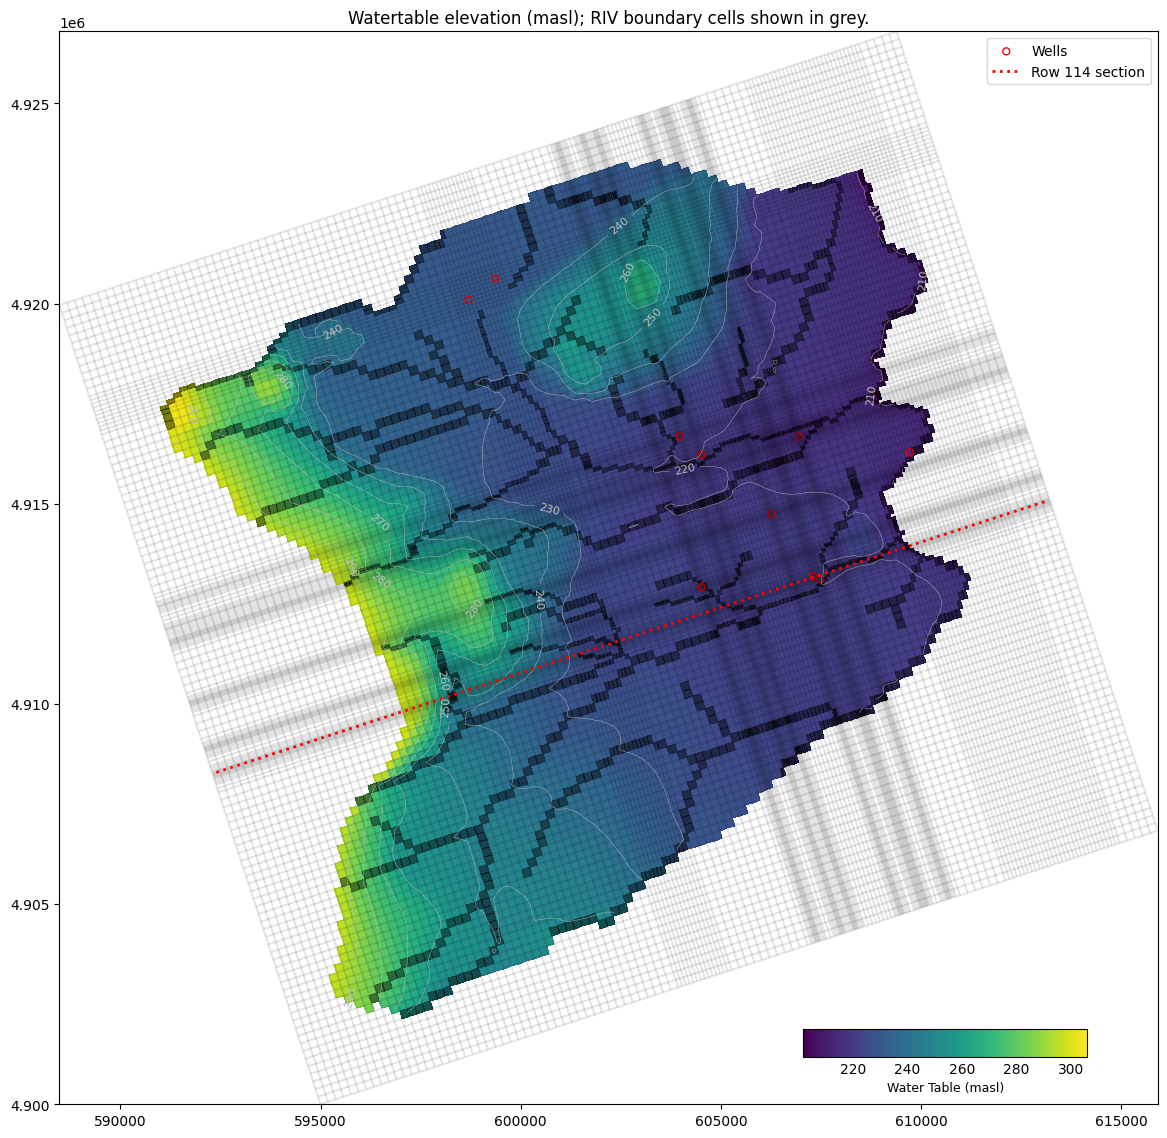

In [14]:
figwidth = 360
figwidth = figwidth / 10 / 2.54  # inches
figheight = figwidth
figsize = (figwidth, figheight)

hds = flopy.utils.HeadFile(root+nam+'/'+nam+'.hds')
head = hds.get_data(totim=hds.get_times()[-1])
wt = flopy.utils.postprocessing.get_water_table(head, gwf.modelgrid)

fig, ax = plt.subplots(figsize=figsize)
pmv = flopy.plot.PlotMapView(gwf, ax=ax)
pltarr = pmv.plot_array(wt)
pmv.plot_grid(colors="#0000001A")

# contours
rnd = 10
vmin = np.floor(np.nanmin(wt) / rnd) * rnd
vmax = np.ceil(np.nanmax(wt) / rnd) * rnd
levels = np.arange(vmin, vmax + rnd, rnd)
cg = pmv.contour_array(wt, levels=levels, linewidths=0.3, colors="0.75")
ax.clabel(cg, inline=True, fontsize=8)
pmv.plot_bc("RIV",color='#00000040')

# add wells
cellids = np.array([cid for cid in wel_spd[0]])  # shape (nwel, 3) -> (k,i,j)
ij = cellids[:, 1:3].astype(int)
x = gwf.modelgrid.xcellcenters[ij[:, 0], ij[:, 1]]
y = gwf.modelgrid.ycellcenters[ij[:, 0], ij[:, 1]]
ax.scatter(x, y, marker="o", s=25, edgecolors="r", facecolors="none", linewidths=1.0, label="Wells")

# add cross-section
xrow = 114
x = gwf.modelgrid.xcellcenters[xrow, :]
y = gwf.modelgrid.ycellcenters[xrow, :]
ax.plot(x, y, color="red", linestyle=":", linewidth=2, label="Row {} section".format(xrow))

cax = plt.axes([0.65, 0.15, 0.2, 0.02])
cbar = plt.colorbar(pltarr, shrink=0.8, orientation="horizontal", cax=cax)
cbar.ax.tick_params(size=0)
cbar.ax.set_xlabel("Water Table (masl)", fontsize=9)

ax.set_aspect("equal")
ax.legend(loc="upper right")
ax.set_title("Watertable elevation (masl); RIV boundary cells shown in grey.")

### Cross-sections

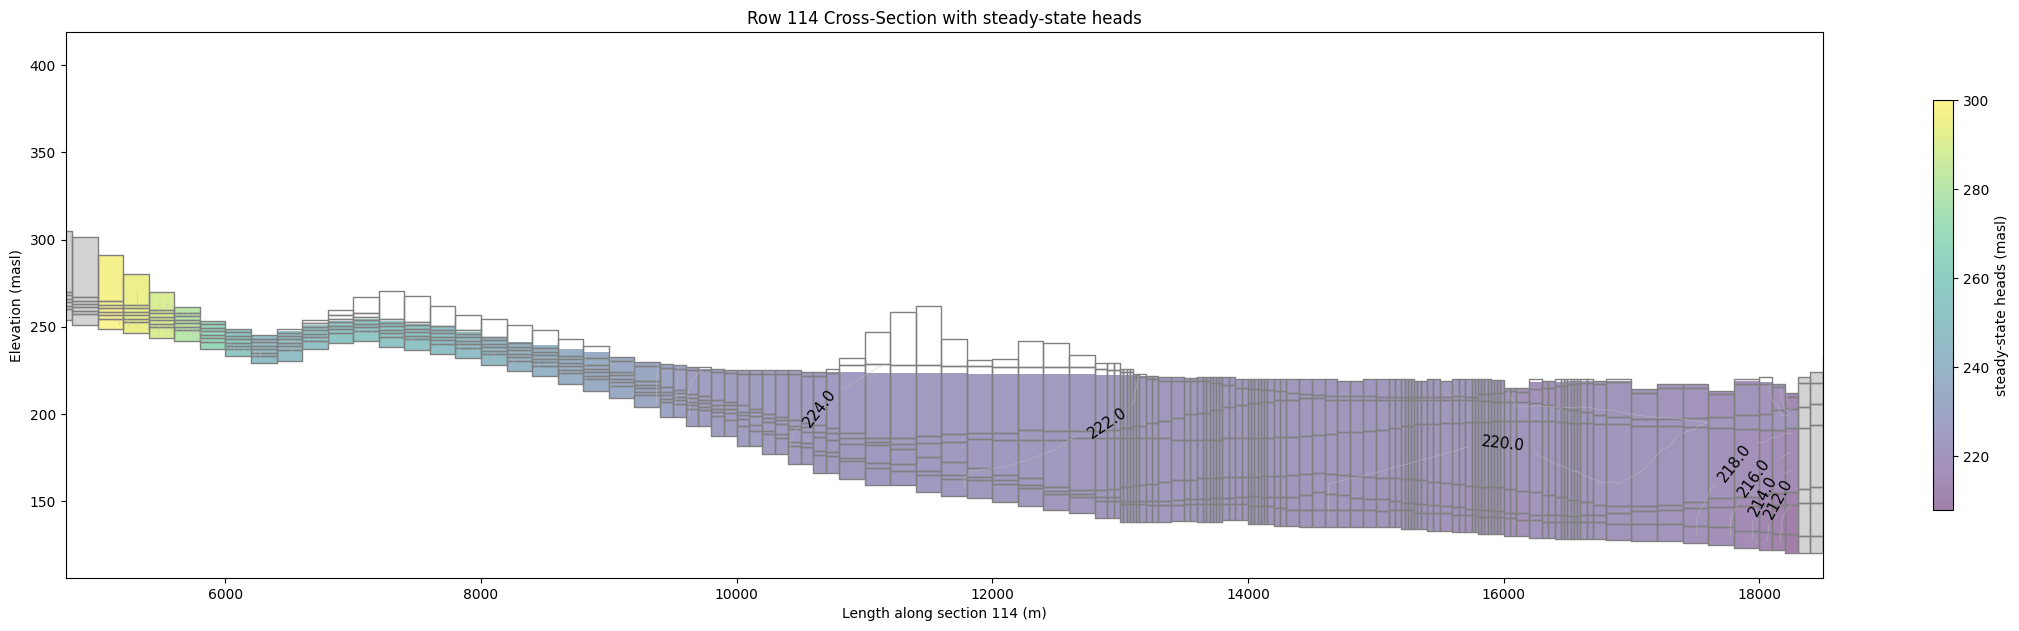

In [15]:
fig, ax = plt.subplots(figsize=(figwidth*2, figheight/2))

xsect = flopy.plot.PlotCrossSection(model=gwf, line={"Row": xrow})
pc = xsect.plot_array(head, head=head, alpha=0.5)
patches = xsect.plot_ibound(head=head, color_noflow="lightgrey")
patches = xsect.plot_bc("WEL", color="pink")
linecollection = xsect.plot_grid()

# add contours
rnd = 2
vmin = np.floor(np.nanmin(wt) / rnd) * rnd
vmax = np.ceil(np.nanmax(wt) / rnd) * rnd
levels = np.arange(vmin, vmax + rnd, rnd)
contour_set = xsect.contour_array(head, head=head, levels=levels, linewidths=0.3, colors="0.75")
plt.clabel(contour_set, fmt="%.1f", colors="k", fontsize=11)

cb = plt.colorbar(pc, shrink=0.75, label="steady-state heads (masl)")
ax.set_xlim(4750, 18500)
ax.set_xlabel("Length along section {} (m)".format(xrow))
ax.set_ylabel("Elevation (masl)")
t = ax.set_title("Row {} Cross-Section with steady-state heads".format(xrow))


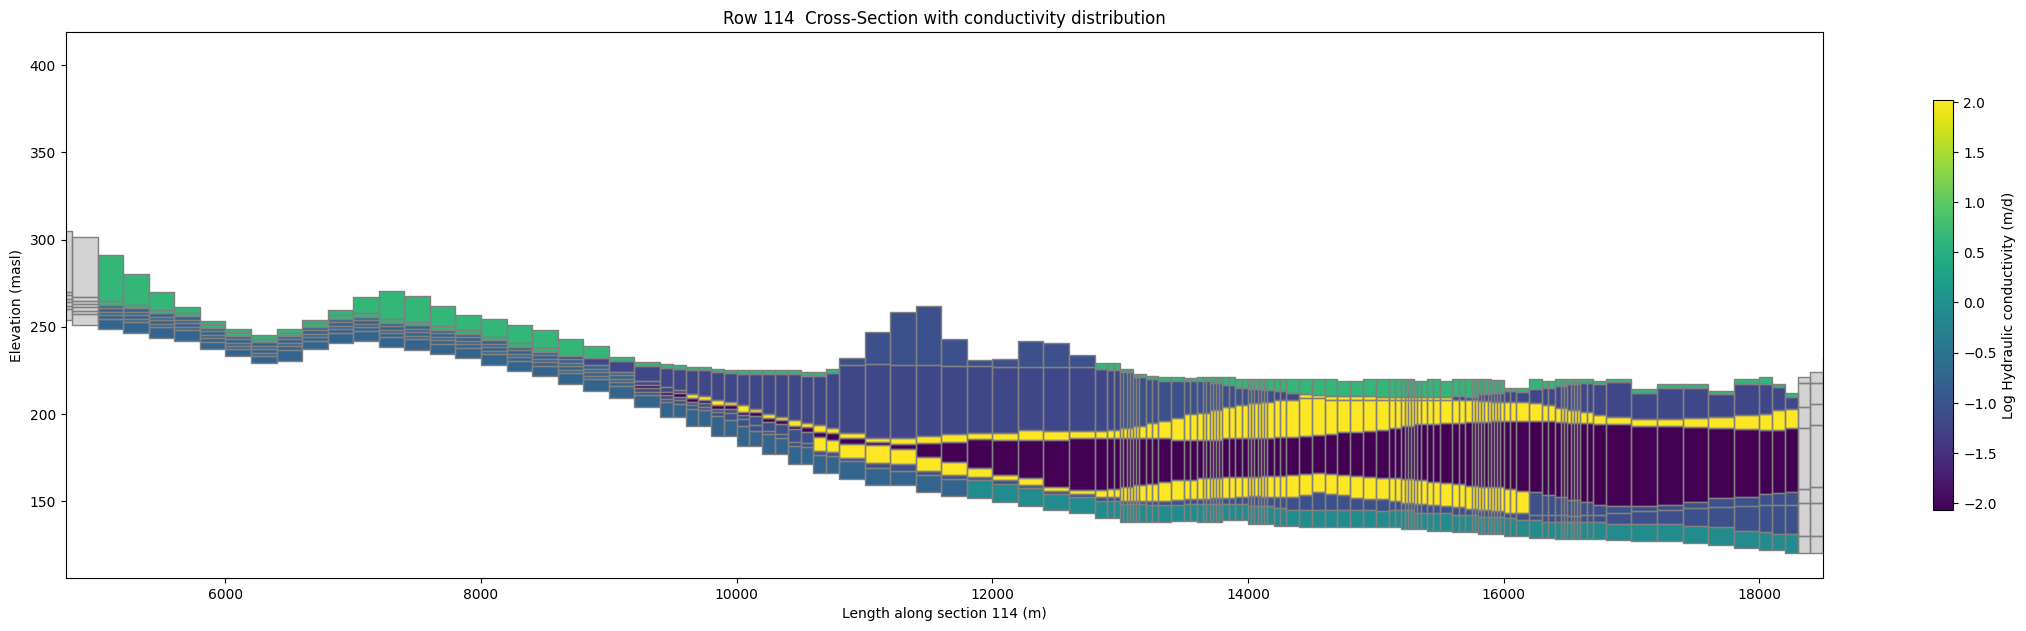

In [16]:
fig, ax = plt.subplots(figsize=(figwidth*2, figheight/2))

xsect = flopy.plot.PlotCrossSection(model=gwf, line={"Row": xrow})
ks = xsect.plot_array(np.log10(k11))
patches = xsect.plot_ibound(color_noflow="lightgrey")
linecollection = xsect.plot_grid()

cb = plt.colorbar(ks, shrink=0.75, label="Log Hydraulic conductivity (m/d)")
ax.set_xlim(4750, 18500)
ax.set_xlabel("Length along section {} (m)".format(xrow))
ax.set_ylabel("Elevation (masl)")
t = ax.set_title("Row {}  Cross-Section with conductivity distribution".format(xrow))

## Particle Tracking

In [20]:
mp = flopy.modpath.Modpath7.create_mp7(
    modelname=nam,
    trackdir="backward",
    flowmodel=gwf,
    model_ws=root+nam,
    exe_name="mp7",
)

### Set particles and build MODPATH model
100 particles are placed at a 35cm radius around each well

In [21]:
wel = gwf.get_package("WEL")
spd = wel.stress_period_data.get_data(kper=0)
cellids = [cid[0] for cid in spd[0]]  # (k,i,j)
cellids = list({tuple(map(int, c)) for c in cellids}) # make unique

nper = 100
theta = np.linspace(0, 2*np.pi, nper, endpoint=False)
r = 0.35
localx = 0.5 + r * np.cos(theta)
localy = 0.5 + r * np.sin(theta)
localz = 0.5  # mid-cell vertically (you can change)

pgs = []
for wi, cid in enumerate(cellids, start=1):
    partlocs = np.repeat(np.array([cid], dtype=int), nper, axis=0)
    pdata = ParticleData(
        partlocs=partlocs,
        structured=True,
        localx=localx,
        localy=localy,
        localz=localz,
    )
    pgs.append(ParticleGroup(particlegroupname=f"WELL_{wi:03d}", particledata=pdata))

mpbas = mp.get_package("MPBAS")  # should exist after create_mp7
mpsim = Modpath7Sim(mp, trackingdirection="backward", particlegroups=pgs)
mp.add_package(mpsim)


C:\Users\mason\AppData\Roaming\Python\Python314\site-packages\flopy\mbase.py:632: UserWarning: Two packages of the same type, Replacing existing 'MPSIM' package.
  warn(
C:\Users\mason\AppData\Roaming\Python\Python314\site-packages\flopy\mbase.py:623: UserWarning: Unit 14 of package MPSIM already in use.
  warn(


#### run particle tracking

In [22]:
mp.write_input()
mp.run_model()

pl = flopy.utils.PathlineFile("{}.mppth".format(root+nam+'/'+nam))
paths = pl.get_alldata()
paths = np.concatenate(paths)

ep = flopy.utils.EndpointFile("{}.mpend".format(root+nam+'/'+nam))
endpoints = ep.get_alldata()

FloPy is using the following executable to run the model: C:\Users\mason\AppData\Local\flopy\bin\mp7.exe

MODPATH Version 7.2.001   
Program compiled May 24 2025 11:46:54 with IFORT compiler (ver. 20.21.7)        
 
 
Run particle tracking simulation ...
Processing Time Step     1 Period     1.  Time =  1.00000E+00  Steady-state flow                                                    

Particle Summary:
         0 particles are pending release.
         0 particles remain active.
       427 particles terminated at boundary faces.
         0 particles terminated at weak sink cells.
       937 particles terminated at weak source cells.
       136 particles terminated at strong source/sink cells.
         0 particles terminated in cells with a specified zone number.
         0 particles were stranded in inactive or dry cells.
         0 particles were unreleased.
         0 particles have an unknown status.
 
Normal termination.                                                        


#### visualize

colour-coded by well

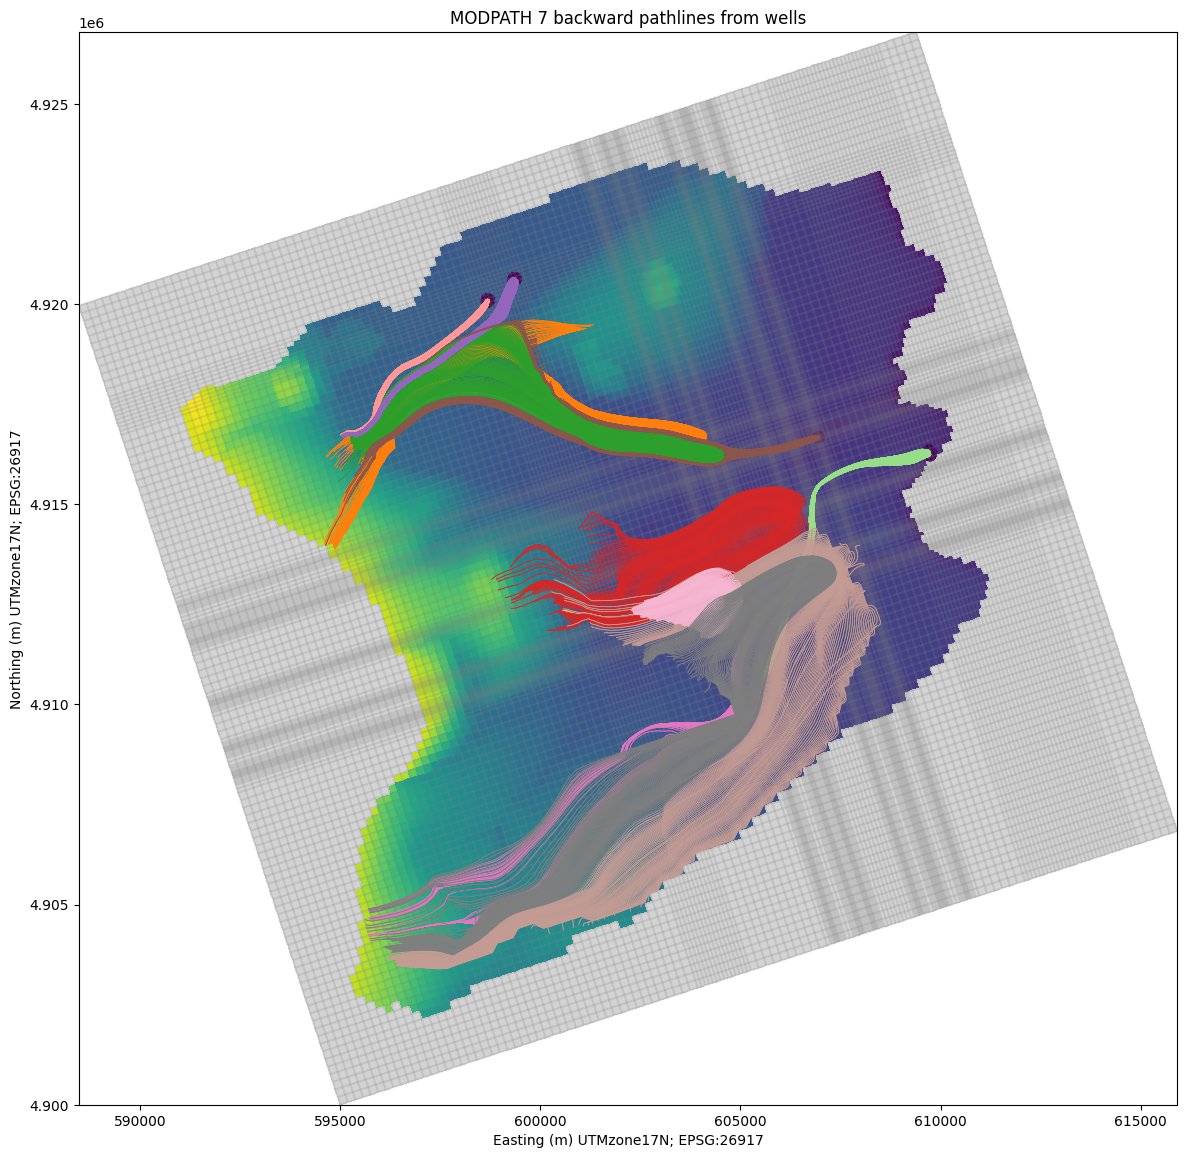

In [23]:
fig, ax = plt.subplots(figsize=figsize)
pmv = flopy.plot.PlotMapView(model=gwf, ax=ax)

pmv.plot_grid(alpha=0.2)
im = pmv.plot_array(wt)
patches = pmv.plot_ibound(color_noflow="lightgrey")

import itertools

groups = np.unique(paths["particlegroup"])
colors = itertools.cycle(plt.cm.tab20.colors)
for g in groups:
    col = next(colors)
    pg = paths[paths["particlegroup"] == g]
    pmv.plot_pathline(pg, layer="all", linewidth=0.5, colors=col)

# endpoints
pmv.plot_endpoint(endpoints, direction="starting", marker="o")

ax.set_xlabel("Easting (m) UTMzone17N; EPSG:26917")
ax.set_ylabel("Northing (m) UTMzone17N; EPSG:26917")
ax.set_aspect("equal")
ax.set_title("MODPATH 7 backward pathlines from wells")
plt.show()